# Macrophages: what RT improves on — composition, behavior, SPP1-TAMs (single cell)

Follow-up to `pscaRtFigures/` focused on monocytes and macrophages. There is no RT-only arm, so the question
is **what RT improves on**: changes in composition, gene expression or behavior that should favor killing
or reduce immunosuppression, either in both CAR backgrounds or specifically with PSCA.

| part | question |
|---|---|
| 1 | How do M1-like, M2-like and their sub-clusters change in proportion (Apoe-, Arg1-, Fn1-high; Mmp12-high; monocyte states)? |
| 2 | What does each macrophage state do? Paired state-vs-other-macrophage pseudobulk DESeq2 + GSEA + curated function modules |
| 3 | What does RT change in each state's behavior, per CAR, and where does RT shift the PSCA effect (CAR × RT)? |
| 4 | What are SPP1-TAMs doing, and what do they do differently with RT? |
| 5 | Scorecard: every RT effect that points toward more killing or less suppression, against the chance expectation |

### Design and statistics
* **Unit = one tumor.** Arms: CyPSCA, CyT72 (TAG72 = non-specific CAR), RTCyPSCA, RTCyT72; Tu1 is the
  irradiated tumor in RT mice, Tu2 the abscopal one. NoTx tumors are shown for context only.
* **Contrasts:**
  - **RT in PSCA / RT in TAG72** = RT − no RT within one CAR at one site.
  - **Pooled RT** = their mean.
  - **CAR × RT** = (RT effect in PSCA) − (RT effect in TAG72).
  - **PSCA effect** = PSCA − TAG72 within an RT stratum.
* **Composition and module scores: exact relabelling p.**
  - At 3 v 3 the smallest p within one CAR is 0.10, so per-CAR rows also show a Welch t p (on log share
    for composition, as in `rtAdvantage/02`).
  - Pooled and CAR × RT can reach p = 0.005.
* **Genes:**
  - pydeseq2 0.5.4 per site (`~ car + rt + car:rt`), five contrasts read from one fit.
  - State identity: paired `~ donor + state` (state vs the other macrophages of the same tumor; the "other"
    pseudobulk is all macrophages minus the state, by subtraction of summed counts).
* **GSEA:** weighted-KS prerank on the Wald statistic (inline engine from `mhcCytotoxExhaustion/03`):
  Hallmark, Reactome and GO BP, set size 15–500, 1,000 permutations, BH within each ranking.
* **Module orientation** (▲ anti-tumor, ▼ suppressive, · context) is the textbook role of each module in
  tumor-associated macrophages. It is a reading aid, not a measured function.
  - **Pvr (CD155) is dual:** TIGIT ligand (inhibitory) and CD226 ligand (activating). It is kept out of
    the oriented modules.
  - **Cd80/Cd86** are co-stimulatory, but CD80 also binds PD-L1 in cis; read them with care.

## 0. Config, style, data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, logging, time, re
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from statsmodels.stats.multitest import multipletests
logging.disable(logging.WARNING)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 300)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SRC = PROJ/"results/mhc_cytotox"; GMT_DIR = PROJ/"data/references/pathways"
OUT = PROJ/"results/rt_advantage/specific_cell_type/macrophages"; OUT.mkdir(parents=True, exist_ok=True)
for f_ in ["pseudobulk_counts.parquet", "pseudobulk_meta.csv", "cell_panel.parquet"]:
    assert (SRC/f_).exists(), f"run code/mhcCytotoxExhaustion/00 first — missing {f_}"
MIN_CELLS, SEED, N_PERM, MIN_SIZE, MAX_SIZE = 10, 0, 1000, 15, 500

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
S_GOOD, S_WARN, S_CRIT = "#0ca30c", "#fab219", "#d03b3b"
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "text.color": INK})

ARMS4 = ["CyPSCA", "RTCyPSCA", "CyT72", "RTCyT72"]
ARM_LAB = {"CyPSCA": "PSCA\nno RT", "RTCyPSCA": "PSCA\n+ RT", "CyT72": "TAG72\nno RT", "RTCyT72": "TAG72\n+ RT"}
CAR_OF = {"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72", "RTCyT72": "TAG72", "NoTx": "none"}
RT_OF = {"CyPSCA": False, "RTCyPSCA": True, "CyT72": False, "RTCyT72": True, "NoTx": False}
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}


def norm_arm(a): return str(a).replace("TAG72", "T72")


def fmt_p(p):
    if p is None or not np.isfinite(p): return "n/a"
    return f"{p:.3f}" if p < 0.1 else f"{p:.2f}"


PB = pd.read_parquet(SRC/"pseudobulk_counts.parquet")
PBM = pd.read_csv(SRC/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
PBM["arm"] = PBM.arm.map(norm_arm)
cp = pd.read_parquet(SRC/"cell_panel.parquet", columns=["sample", "arm", "site", "ct2", "ct3", "lvl4", "SPP1_TAM"])
cp["arm"] = cp.arm.map(norm_arm)
print(f"{len(PB)} pseudobulks x {PB.shape[1]:,} genes | {len(cp):,} cells")

# ---- states -------------------------------------------------------------------------------------
# lvl3 sub-cluster -> (display name, lvl2 parent, pseudobulk group). M1-like == IFN-stimulated mac and
# Intermediate == Mmp12-high mac are identical cell sets; non-classical mono == patrolling mono.
SUBS = [("IFN_stimulated_Mac", "M1-like (IFN-stim)", "M1_like_Mac", "IFN_stimulated_Mac"),
        ("Apoe_high_Mac", "M2: Apoe-high", "M2_like_Mac", "Apoe_high_Mac"),
        ("Arg1_high_Mac", "M2: Arg1-high", "M2_like_Mac", "Arg1_high_Mac"),
        ("Fn1_high_Mac", "M2: Fn1-high", "M2_like_Mac", "Fn1_high_Mac"),
        ("Mmp12_high_Mac", "Intermediate (Mmp12-high)", "Intermediate_Mac", "Intermediate_Mac"),
        ("IFN_stimulated_Mono", "Classical mono: IFN-stim", "Classical_Mono", "IFN_stimulated_Mono"),
        ("Phagocytic_Mono", "Classical mono: phagocytic", "Classical_Mono", "Phagocytic_Mono"),
        ("Patrolling_Mono", "Non-classical (patrolling) mono", "Nonclassical_Mono", "Nonclassical_Mono")]
SUB_NAME = {s: n for s, n, _, _ in SUBS}
SUB_NAME.update({"Spp1_high": "Spp1-high mac", "Trem2_high": "Trem2-high mac", "Spp1_Trem2_high": "Spp1+Trem2 double-high",
                 "Spp1_Trem2_Apoe_high": "Spp1+Trem2+Apoe triple-high", "Apoe_high": "Apoe-high mac (gene)"})
MAC_SUBS = ["IFN_stimulated_Mac", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Mmp12_high_Mac"]
MONOMAC_CT2 = ["M1_like_Mac", "M2_like_Mac", "Intermediate_Mac", "Classical_Mono", "Nonclassical_Mono"]
MAC_CT2 = ["M1_like_Mac", "M2_like_Mac", "Intermediate_Mac"]
# pseudobulk groups used for behavior (display name)
BEH = {"IFN_stimulated_Mac": "M1-like\n(IFN-stim)", "Apoe_high_Mac": "M2:\nApoe-high", "Arg1_high_Mac": "M2:\nArg1-high",
       "Fn1_high_Mac": "M2:\nFn1-high", "M2_like_Mac": "M2-like\n(all)", "Intermediate_Mac": "Inter-\nmediate",
       "SPP1_TAM": "SPP1-TAM\n(signature)", "SPP1_alice": "SPP1+ mac\n(lvl4)", "Classical_Mono": "Classical\nmono",
       "IFN_stimulated_Mono": "Mono:\nIFN-stim", "Phagocytic_Mono": "Mono:\nphagocytic", "Nonclassical_Mono": "Non-class.\nmono"}
FIT_GROUPS = list(BEH)
M3_GROUPS_ = ["IFN_stimulated_Mac", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Intermediate_Mac", "SPP1_TAM",
              "Classical_Mono", "Nonclassical_Mono"]


def flat(lbl): return lbl.replace("-\n", "-").replace("\n", " ")

1158 pseudobulks x 22,949 genes | 93,548 cells


## 1. Statistics engine (inline; same definitions as `mhcCytotoxFigures` / `pscaRtFigures`)

In [2]:
def _cell(v, meta, A, B, site):
    idx = [i for i in meta.index[meta.arm.isin([A, B]) & (meta.site == site)] if np.isfinite(v.get(i, np.nan))]
    a = v[[i for i in idx if meta.loc[i, "arm"] == A]]; b = v[[i for i in idx if meta.loc[i, "arm"] == B]]
    if len(a) < 2 or len(b) < 2: return None
    x = np.r_[a.values, b.values]; k = len(a)
    null = [a.mean() - b.mean()]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        m = np.isin(np.arange(len(x)), c); null.append(x[m].mean() - x[~m].mean())
    ss = ((a - a.mean()) ** 2).sum() + ((b - b.mean()) ** 2).sum()
    return dict(d=a.mean() - b.mean(), null=np.array(null), ss=ss, df=len(a) + len(b) - 2,
                inv=1 / len(a) + 1 / len(b), nA=len(a), nB=len(b), a=a.values, b=b.values)


def _combine(nulls, how="mean", cap=60000, seed=SEED):
    g_ = np.random.default_rng(seed); out = nulls[0]
    for k, nb in enumerate(nulls[1:], start=2):
        out = ((out[:, None] * (k - 1) + nb[None, :]) / k).ravel() if how == "mean" else (out[:, None] - nb[None, :]).ravel()
        if len(out) > cap: out = np.r_[out[:1], g_.choice(out[1:], cap, replace=False)]
    return out


def _p(null): return float((np.abs(null) >= abs(null[0]) - 1e-12).mean())


def stratum(v, meta, cells):
    cs = [c for c in (_cell(v, meta, *cell) for cell in cells) if c is not None]
    if not cs: return None
    K = len(cs); df = sum(c["df"] for c in cs); s2 = sum(c["ss"] for c in cs) / max(df, 1)
    welch = stats.ttest_ind(cs[0]["a"], cs[0]["b"], equal_var=False).pvalue if K == 1 else np.nan
    return dict(d=np.mean([c["d"] for c in cs]), se=np.sqrt(s2 * sum(c["inv"] for c in cs)) / K, df=df,
                null=_combine([c["null"] for c in cs]), n=" + ".join(f"{c['nA']}v{c['nB']}" for c in cs), welch=welch)


EFFECTS = {
    "RT Tu1":   [("PSCA", [("RTCyPSCA", "CyPSCA", 1)]), ("TAG72", [("RTCyT72", "CyT72", 1)])],
    "RT Tu2":   [("PSCA", [("RTCyPSCA", "CyPSCA", 2)]), ("TAG72", [("RTCyT72", "CyT72", 2)])],
    "PSCA Tu1": [("no RT", [("CyPSCA", "CyT72", 1)]), ("RT", [("RTCyPSCA", "RTCyT72", 1)])],
    "PSCA Tu2": [("no RT", [("CyPSCA", "CyT72", 2)]), ("RT", [("RTCyPSCA", "RTCyT72", 2)])],
}


def effect(v, meta, eff, scale=1.0):
    out = {}
    st = [(lab, stratum(v, meta, cells)) for lab, cells in EFFECTS[eff]]
    for lab, s in st:
        if s is None: continue
        h = stats.t.ppf(0.975, s["df"]) * s["se"]
        out[lab] = dict(est=s["d"] * scale, lo=(s["d"] - h) * scale, hi=(s["d"] + h) * scale,
                        p=_p(s["null"]), welch=s["welch"], n=s["n"])
    if all(s is not None for _, s in st):
        (l1, s1), (l2, s2) = st
        df = s1["df"] + s2["df"]; m = (s1["d"] + s2["d"]) / 2
        h = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2) / 2
        out["pooled"] = dict(est=m * scale, lo=(m - h) * scale, hi=(m + h) * scale,
                             p=_p(_combine([s1["null"], s2["null"]], "mean")), welch=np.nan)
        hi_, lo_ = (s2, s1) if eff.startswith("PSCA") else (s1, s2)
        it = hi_["d"] - lo_["d"]; hh = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2)
        out["CARxRT"] = dict(est=it * scale, lo=(it - hh) * scale, hi=(it + hh) * scale,
                             p=_p(_combine([hi_["null"], lo_["null"]], "diff")), welch=np.nan)
    return out


def effect_rows(v, meta, scale=1.0, **keys):
    rows = []
    for eff in EFFECTS:
        for part, d in effect(v, meta, eff, scale).items():
            rows.append({**keys, "effect": eff, "part": part, **d})
    return rows


def best_p(r):
    """Per-CAR rows: Welch t p (exact floor 0.10 at 3 v 3); pooled / CAR x RT: exact p."""
    return r["welch"] if r["part"] in ("PSCA", "TAG72", "no RT", "RT") and np.isfinite(r.get("welch", np.nan)) else r["p"]

## 2. Part 1 — composition of macrophage and monocyte states
Three denominators: share of **all cells**, share of the **mono/mac compartment** (the five lvl2
mono/mac labels), and share **within the lvl2 parent** (e.g. Arg1-high as a share of M2-like).
SPP1-TAM shares are taken among **macrophages** (M1 + M2 + Intermediate).

In [3]:
cp_t = cp.copy()
smeta = cp_t.groupby("sample")[["arm", "site"]].first()
n_all = cp_t.groupby("sample").size()
mm = cp_t[cp_t.ct2.isin(MONOMAC_CT2)]
n_mm = mm.groupby("sample").size().reindex(n_all.index).fillna(0)
mac = cp_t[cp_t.ct2.isin(MAC_CT2)]
n_mac = mac.groupby("sample").size().reindex(n_all.index).fillna(0)
cnt3 = mm.groupby(["sample", "ct3"]).size().unstack(fill_value=0).reindex(n_all.index).fillna(0)
cnt2 = mm.groupby(["sample", "ct2"]).size().unstack(fill_value=0).reindex(n_all.index).fillna(0)
parent_of = {s: p for s, _, p, _ in SUBS}

F = {}   # feature -> per-sample share in %
for s, name, par, _ in SUBS:
    F[(s, "% of all cells")] = cnt3[s] / n_all * 100
    F[(s, "% of mono/mac")] = cnt3[s] / n_mm * 100
    if cnt2.columns.isin([par]).any() and (cnt3.columns[cnt3.columns.map(parent_of.get) == par].size > 1):
        F[(s, f"% of parent")] = cnt3[s] / cnt2[par].replace(0, np.nan) * 100
for c in MONOMAC_CT2:
    F[(c, "% of all cells")] = cnt2[c] / n_all * 100
    F[(c, "% of mono/mac")] = cnt2[c] / n_mm * 100
F[("SPP1_TAM", "% of macrophages")] = mac.groupby("sample").SPP1_TAM.mean().reindex(n_all.index) * 100
F[("SPP1_alice", "% of macrophages")] = (mac.lvl4 == "Spp1_pos_mac").groupby(mac["sample"]).mean().reindex(n_all.index) * 100
for s in MAC_SUBS:   # SPP1+ (lvl4) within each macrophage sub-cluster
    sub = mac[mac.ct3 == s]
    F[(f"SPP1+ in {s}", "% of sub-cluster")] = (sub.lvl4 == "Spp1_pos_mac").groupby(sub["sample"]).mean().reindex(n_all.index) * 100
# ---- gene-defined high macrophages: ONE global cut (top quartile over all treated-tumor macrophages) ----
# A fixed cut keeps shares comparable across arms (as for SPP1-TAM). Whether a drop means fewer cells of a type
# or lower expression in the same cells is separated in section 8b.
HIGH_GENES = ["Spp1", "Trem2", "Apoe"]
cpg = pd.read_parquet(SRC/"cell_panel.parquet", columns=["sample", "arm", "site", "ct2", "ct3", "total_counts"] + HIGH_GENES)
cpg["arm"] = cpg.arm.map(norm_arm)
macg = cpg[cpg.ct2.isin(MAC_CT2)].copy()
HIGH_CUT = {}
for g in HIGH_GENES:
    macg[g] = np.log1p(macg[g] / macg.total_counts * 1e4)
    x = macg.loc[macg.arm != "NoTx", g]; q = float(np.quantile(x, 0.75))
    HIGH_CUT[g] = q
    macg[f"{g}_high"] = (macg[g] >= q) if q > 0 else (macg[g] > 0)
macg["Spp1_Trem2_high"] = macg.Spp1_high & macg.Trem2_high
macg["Spp1_Trem2_Apoe_high"] = macg.Spp1_Trem2_high & macg.Apoe_high
HIGHS = {"Spp1_high": "Spp1-high mac", "Trem2_high": "Trem2-high mac", "Spp1_Trem2_high": "Spp1+Trem2 double-high",
         "Spp1_Trem2_Apoe_high": "Spp1+Trem2+Apoe triple-high", "Apoe_high": "Apoe-high mac (gene)"}
for h in HIGHS:
    k = macg.groupby("sample")[h].sum().reindex(n_all.index).fillna(0)
    F[(h, "% of macrophages")] = k / n_mac.replace(0, np.nan) * 100
    F[(h, "% of mono/mac")] = k / n_mm * 100
    F[(h, "% of all cells")] = k / n_all * 100
print("global cuts (log1p CP10k):", {g: round(v, 3) for g, v in HIGH_CUT.items()},
      "| share of treated-tumor macrophages above cut:",
      {h: round(float(macg.loc[macg.arm != "NoTx", h].mean()), 3) for h in HIGHS})

FEAT = pd.DataFrame(F); FEAT.columns = [f"{a} | {b}" for a, b in FEAT.columns]
FEAT = FEAT.join(smeta)
RATIO = np.log2((cnt2["M1_like_Mac"] + 1) / (cnt2["M2_like_Mac"] + 1)).rename("log2 M1:M2")
FEAT["log2 M1:M2 | ratio"] = RATIO
FEAT.to_csv(OUT/"composition_per_sample.csv")

meta_s = FEAT[["arm", "site"]]
crow = []
for col in [c for c in FEAT.columns if " | " in c]:
    v = FEAT[col]
    is_ratio = col.endswith("| ratio")
    vv = v if is_ratio else np.log2(v + 0.01)          # effects on log2 share: est = log2 fold change
    for r in effect_rows(vv, meta_s, feature=col.split(" | ")[0], denominator=col.split(" | ")[1]):
        crow.append(r)
COMP = pd.DataFrame(crow)
# arithmetic means for reading (pp)
means = FEAT[FEAT.arm.isin(ARMS4)].groupby(["arm", "site"]).mean(numeric_only=True)
COMP["p_use"] = COMP.apply(best_p, axis=1)
COMP["q"] = np.nan
for _, d in COMP.groupby(["denominator", "effect", "part"]):
    ok = d.p_use.notna()
    if ok.sum(): COMP.loc[d.index[ok], "q"] = multipletests(d.p_use[ok], method="fdr_bh")[1]
COMP.drop(columns=[c for c in COMP.columns if c in ("null",)], errors="ignore").to_csv(OUT/"composition_effects.csv", index=False)

show = COMP[(COMP.p_use < 0.10) & COMP.denominator.isin(["% of mono/mac", "% of parent", "% of macrophages", "% of sub-cluster", "ratio"])]
print("Composition effects with p < 0.10 (est = log2 fold change; per-CAR p = Welch on log share):")
print(show[["feature", "denominator", "effect", "part", "est", "p", "welch", "p_use", "q"]].round(3).to_string(index=False))
print("\nmean % of mono/mac, Tu1:")
print(means.xs(1, level="site")[[c for c in means.columns if "% of mono/mac" in c and c.split(" | ")[0] in SUB_NAME]]
      .rename(columns=lambda c: SUB_NAME[c.split(" | ")[0]]).round(1).T.to_string())

global cuts (log1p CP10k): {'Spp1': 2.142, 'Trem2': 1.149, 'Apoe': 3.866} | share of treated-tumor macrophages above cut: {'Spp1_high': 0.25, 'Trem2_high': 0.25, 'Spp1_Trem2_high': 0.122, 'Spp1_Trem2_Apoe_high': 0.089, 'Apoe_high': 0.25}


Composition effects with p < 0.10 (est = log2 fold change; per-CAR p = Welch on log share):
               feature      denominator   effect   part    est     p  welch  p_use     q
    IFN_stimulated_Mac    % of mono/mac   RT Tu1   PSCA  0.373 0.100  0.094  0.094 0.424
    IFN_stimulated_Mac    % of mono/mac PSCA Tu1 pooled  0.740 0.005    NaN  0.005 0.010
    IFN_stimulated_Mac    % of mono/mac PSCA Tu2  no RT  1.211 0.100  0.019  0.019 0.112
    IFN_stimulated_Mac    % of mono/mac PSCA Tu2     RT  0.804 0.100  0.020  0.020 0.116
    IFN_stimulated_Mac    % of mono/mac PSCA Tu2 pooled  1.008 0.005    NaN  0.005 0.015
         Apoe_high_Mac    % of mono/mac PSCA Tu1  no RT -1.148 0.100  0.016  0.016 0.049
         Apoe_high_Mac    % of mono/mac PSCA Tu1 pooled -0.884 0.015    NaN  0.015 0.025
         Apoe_high_Mac    % of mono/mac PSCA Tu2  no RT -1.016 0.100  0.063  0.063 0.162
         Apoe_high_Mac    % of mono/mac PSCA Tu2 pooled -0.877 0.010    NaN  0.010 0.023
         Arg1_high

## 3. Function modules (curated, oriented) and per-sample module scores

In [4]:
def present(gl): return [g for g in gl if g in PB.columns]


NECTIN2 = "Nectin2" if "Nectin2" in PB.columns else ("Pvrl2" if "Pvrl2" in PB.columns else None)
MODULES = {   # name: (orientation, genes); +1 anti-tumor, -1 suppressive, 0 context
    "MHC-II presentation":        (+1, ["H2-Aa", "H2-Ab1", "H2-Eb1", "H2-DMa", "H2-DMb1", "Cd74", "Ciita", "Ctss"]),
    "MHC-I presentation":         (+1, ["H2-K1", "H2-D1", "B2m", "Tap1", "Tap2", "Tapbp", "Psmb8", "Psmb9", "Psmb10", "Nlrc5", "Erap1"]),
    "IFN-γ response core":        (+1, ["Stat1", "Irf1", "Gbp2", "Gbp5", "Gbp7", "Igtp", "Iigp1", "Cxcl9", "Cxcl10"]),
    "T/NK-recruiting chemokines": (+1, ["Cxcl9", "Cxcl10", "Cxcl16", "Ccl5", "Ccl3", "Ccl4"]),
    "Inflammatory cytokines":     (+1, ["Il1b", "Tnf", "Il12b", "Il6", "Il27", "Il18", "Il15"]),
    "Co-stimulation":             (+1, ["Cd80", "Cd86", "Cd40", "Tnfsf9", "Icosl", "Cd70"]),
    "Fc-receptor phagocytosis":   (+1, ["Fcgr1", "Fcgr3", "Fcgr4", "Fcer1g", "Syk"]),
    "ROS / NO killing":           (+1, ["Nos2", "Cybb", "Ncf1", "Ncf2", "Ncf4", "Cyba"]),
    "T-cell inhibitory ligands":  (-1, ["Cd274", "Pdcd1lg2", "Lgals9", "Vsir"] + ([NECTIN2] if NECTIN2 else [])),
    "Phagocytosis checkpoints":   (-1, ["Sirpa", "Lilrb4a", "Siglece", "Pirb"]),
    "Suppressive mediators":      (-1, ["Arg1", "Il10", "Tgfb1", "Ptgs2", "Ptges", "Ido1", "Il4i1", "Hmox1", "Vegfa", "Chil3", "Retnla"]),
    "Treg-recruiting chemokines": (-1, ["Ccl17", "Ccl22", "Ccl1"]),
    "Adenosine axis":             (-1, ["Entpd1", "Nt5e", "Adora2a", "Adora2b"]),
    "M2 / scavenger receptors":   (-1, ["Mrc1", "Cd163", "Msr1", "Stab1", "Lyve1", "F13a1", "Folr2", "Cd36"]),
    "TREM2 / lipid TAM":          (-1, ["Trem2", "Apoe", "Lpl", "Spp1", "Gpnmb", "Fabp5", "Cd9", "Lgals3"]),
    "Efferocytosis":              (-1, ["Mertk", "Axl", "Gas6", "Timd4", "Mfge8", "Itgb5"]),
    "CCR2 (monocyte) chemokines": (0, ["Ccl2", "Ccl7", "Ccl12"]),
    "Complement C1q":             (0, ["C1qa", "C1qb", "C1qc"]),
    "NR4A early response":        (0, ["Nr4a1", "Nr4a2", "Nr4a3"]),
    "Proliferation":              (0, ["Mki67", "Top2a", "Ccnb2", "Cdk1"]),
}
MODULES = {k: (o, present(g)) for k, (o, g) in MODULES.items()}
SPOT = ["Ciita", "Pvr", "Cd86", "Cd80", "Il1b", "Cd274", "Nos2", "Cxcl9", "Arg1", "Mrc1", "Trem2", "Spp1"]
ORI = {k: o for k, (o, _) in MODULES.items()}
GENE_ORI = {"Ciita": 1, "Cd86": 1, "Cd80": 1, "Il1b": 1, "Nos2": 1, "Cxcl9": 1, "Cd274": -1, "Arg1": -1, "Mrc1": -1,
            "Trem2": -1, "Spp1": -1, "Pvr": 0}      # Pvr: TIGIT (inhibitory) and CD226 (activating) ligand
ORI.update({f"gene: {g}": o for g, o in GENE_ORI.items()})
TAG = {1: "▲", -1: "▼", 0: "·"}
pd.DataFrame([(k, o, " ".join(g)) for k, (o, g) in MODULES.items()], columns=["module", "orientation", "genes"]) \
  .to_csv(OUT/"modules.csv", index=False)

L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)


def group_scores(group, min_cells=MIN_CELLS):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells)]
    Lg = L.loc[d.index]; expressed = Lg.columns[(Lg.mean() >= 1.0).values]
    tr = (d.arm != "NoTx").values
    Z = (Lg[expressed] - Lg.loc[tr, expressed].mean()) / Lg.loc[tr, expressed].std().replace(0, np.nan)
    Z = Z.dropna(axis=1); Z.index = d["sample"].values
    S = {}
    for k, (_, gl) in MODULES.items():
        g_ = [g for g in gl if g in Z.columns]
        if len(g_) >= 2: S[k] = Z[g_].mean(1)
    for g in SPOT:
        if g in Z.columns: S[f"gene: {g}"] = Z[g]
    S = pd.DataFrame(S)
    meta = d.set_index("sample")[["arm", "site", "n_cells"]]
    sdw = S.join(meta)[meta.arm != "NoTx"].groupby(["arm", "site"])[list(S.columns)].var().mean().pow(0.5)
    return S, meta, sdw


mrow, SCORES = [], {}
for g in FIT_GROUPS:
    S, meta, sdw = group_scores(g)
    SCORES[g] = (S, meta)
    for col in S.columns:
        sc = 1 / sdw[col] if np.isfinite(sdw[col]) and sdw[col] > 0 else np.nan
        mrow += effect_rows(S[col], meta, scale=sc, group=g, module=col)
MOD = pd.DataFrame(mrow)
MOD["orientation"] = MOD.module.map(lambda m: ORI.get(m, 0))
MOD["p_use"] = MOD.apply(best_p, axis=1)
MOD["advantage"] = MOD.orientation * MOD.est
MOD["q"] = np.nan
for _, d in MOD.groupby(["effect", "part"]):
    ok = d.p_use.notna()
    if ok.sum(): MOD.loc[d.index[ok], "q"] = multipletests(d.p_use[ok], method="fdr_bh")[1]
MOD.to_csv(OUT/"module_effects.csv", index=False)
print(f"module effects: {len(MOD):,} rows over {MOD.group.nunique()} groups x {MOD.module.nunique()} modules/genes")

module effects: 6,016 rows over 12 groups x 32 modules/genes


## 4. Pseudobulk DESeq2 — per-site CAR × RT fits and state-vs-other-macrophage fits (cached)

In [5]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
INF = DefaultInference(n_cpus=4)
FOCUS = sorted({g for _, gl in MODULES.values() for g in gl} | set(SPOT))
SITE_CACHE, STATE_CACHE = OUT/"de_persite_carxrt.parquet", OUT/"de_state_vs_rest.parquet"


def fit_site(group, site):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS) & (PBM.site == site) & PBM.arm.isin(ARMS4)]
    cnt = d.arm.value_counts().reindex(ARMS4).fillna(0).astype(int)
    if (cnt < 2).any(): return None, f"cells {cnt.to_dict()}"
    meta = pd.DataFrame(index=d.index)
    meta["car"] = pd.Categorical(d.arm.map(CAR_OF), ["TAG72", "PSCA"])
    meta["rt"] = pd.Categorical(np.where(d.arm.map(RT_OF), "RT", "noRT"), ["noRT", "RT"])
    X = PB.loc[d.index]
    keep = (((X > 0).sum(0) >= 3) & (X.sum(0) >= 10 * len(X))) | (X.columns.isin(FOCUS) & ((X > 0).sum(0) >= 2))
    dds = DeseqDataSet(counts=X.loc[:, keep], metadata=meta, design="~ car + rt + car:rt", inference=INF, quiet=True)
    dds.deseq2()
    cols = list(dds.obsm["design_matrix"].columns)
    ic = [c for c in cols if ":" in c][0]; cc = [c for c in cols if c.startswith("car") and ":" not in c][0]
    rc = [c for c in cols if c.startswith("rt") and ":" not in c][0]
    out = []
    for name, w in {"PSCA_noRT": {cc: 1}, "PSCA_RT": {cc: 1, ic: 1}, "RT_in_TAG72": {rc: 1},
                    "RT_in_PSCA": {rc: 1, ic: 1}, "CARxRT": {ic: 1}}.items():
        v = np.zeros(len(cols))
        for c, x in w.items(): v[cols.index(c)] = x
        st = DeseqStats(dds, contrast=v, inference=INF, quiet=True); st.summary()
        r = st.results_df.copy(); r["gene"] = r.index; r["contrast"] = name; out.append(r)
    r = pd.concat(out, ignore_index=True)
    r["group"], r["site"], r["n"] = group, site, " ".join(f"{a}:{n}" for a, n in cnt.items())
    return r, "ok"


STATE_REST = {"IFN_stimulated_Mac": "mac_all", "Apoe_high_Mac": "mac_all", "Arg1_high_Mac": "mac_all",
              "Fn1_high_Mac": "mac_all", "Intermediate_Mac": "mac_all", "SPP1_TAM": "mac_all", "SPP1_alice": "mac_all"}


def rest_counts(state, whole="mac_all"):
    """Per treated sample: (state counts, whole-minus-state counts), both with >= MIN_CELLS cells."""
    ds = PBM[(PBM.group == state) & (PBM.arm != "NoTx")].set_index("sample")
    dw = PBM[(PBM.group == whole) & (PBM.arm != "NoTx")].set_index("sample")
    S_, R_, keep = [], [], []
    for s in ds.index.intersection(dw.index):
        n_s, n_r = ds.loc[s, "n_cells"], dw.loc[s, "n_cells"] - ds.loc[s, "n_cells"]
        if n_s < MIN_CELLS or n_r < MIN_CELLS: continue
        a = PB.loc[f"{state}|{s}"]; b = PB.loc[f"{whole}|{s}"] - a
        assert (b >= -1e-6).all(), f"{state} is not a subset of {whole} in {s}"
        S_.append(a.rename(s)); R_.append(b.clip(lower=0).rename(s)); keep.append(s)
    return pd.DataFrame(S_), pd.DataFrame(R_), keep


def fit_state(state):
    A, B, keep = rest_counts(state, STATE_REST[state])
    X = pd.concat([A.set_axis([f"{s}|state" for s in keep]), B.set_axis([f"{s}|rest" for s in keep])]).round().astype(int)
    meta = pd.DataFrame({"donor": [k.split("|")[0] for k in X.index],
                         "state": pd.Categorical([k.split("|")[1] for k in X.index], ["rest", "state"])}, index=X.index)
    keepg = (((X > 0).sum(0) >= 6) & (X.sum(0) >= 10 * len(X))) | (X.columns.isin(FOCUS) & ((X > 0).sum(0) >= 4))
    dds = DeseqDataSet(counts=X.loc[:, keepg], metadata=meta, design="~ donor + state", inference=INF, quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["state", "state", "rest"], inference=INF, quiet=True); st.summary()
    r = st.results_df.copy(); r["gene"] = r.index; r["state"] = state; r["n_samples"] = len(keep)
    return r


t0 = time.time()
if SITE_CACHE.exists():
    DS = pd.read_parquet(SITE_CACHE)
else:
    res = []
    for g in FIT_GROUPS:
        for s in (1, 2):
            r, msg = fit_site(g, s); print(f"  per-site {g:20s} Tu{s}: {msg}  ({time.time()-t0:.0f}s)")
            if r is not None: res.append(r)
    DS = pd.concat(res, ignore_index=True); DS.to_parquet(SITE_CACHE)
if STATE_CACHE.exists():
    DST = pd.read_parquet(STATE_CACHE)
else:
    DST = pd.concat([fit_state(s) for s in STATE_REST], ignore_index=True); DST.to_parquet(STATE_CACHE)
print(f"per-site fits: {DS.groupby(['group', 'site']).ngroups}; state fits: {DST.state.nunique()} "
      f"(n samples {DST.groupby('state').n_samples.first().to_dict()}); {time.time()-t0:.0f}s")
print("\ngenome-wide padj < 0.05, per-site fits:")
print(DS[DS.padj < 0.05].groupby(["contrast", "site", "group"]).size().unstack([0, 1]).fillna(0).astype(int).to_string())

per-site fits: 24; state fits: 7 (n samples {'Apoe_high_Mac': 23, 'Arg1_high_Mac': 23, 'Fn1_high_Mac': 23, 'IFN_stimulated_Mac': 23, 'Intermediate_Mac': 23, 'SPP1_TAM': 23, 'SPP1_alice': 23}); 0s

genome-wide padj < 0.05, per-site fits:
contrast            CARxRT PSCA_RT      PSCA_noRT      RT_in_PSCA    RT_in_TAG72
site                     1       1    2         1    2          1  2           1
group                                                                           
Apoe_high_Mac            0     193   31        51   99         14  0           0
Arg1_high_Mac            2     112   75       120  113          8  1           0
Classical_Mono           5     498  188       273  427         22  0           2
Fn1_high_Mac             0      55   19        25   22          0  0           0
IFN_stimulated_Mac       0     437  165       226  434         29  0           0
IFN_stimulated_Mono      0     304  169       188  316         14  0           1
Intermediate_Mac         0     461

## 5. GSEA (Hallmark, Reactome, GO BP) on every ranking (cached)

In [6]:
def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in ["mh.all.v2026.1.Mm.symbols.gmt", "m2.cp.reactome.v2026.1.Mm.symbols.gmt", "m5.go.bp.v2026.1.Mm.symbols.gmt"]:
    GMT.update(read_gmt(GMT_DIR/f_))
print(f"{len(GMT):,} gene sets")


def _es_at_hits(pos, wcum, Wtot, N, n):
    i = np.arange(1, n + 1)
    after = wcum / Wtot
    before = np.concatenate([np.zeros(pos.shape[:-1] + (1,)), wcum[..., :-1]], axis=-1) / Wtot
    dev = np.concatenate([after - (pos + 1 - i) / (N - n), before - (pos - i + 1) / (N - n)], axis=-1)
    hi, lo = np.maximum(dev.max(axis=-1), 0.0), np.minimum(dev.min(axis=-1), 0.0)
    return np.where(hi >= -lo, hi, lo)


def gsea_prerank(ranking, sets, n_perm=N_PERM, seed=SEED):
    r = ranking.dropna().sort_values(ascending=False)
    w, N = np.abs(r.to_numpy(float)), len(r)
    idx = pd.Series(np.arange(N), index=r.index)
    POS = {}
    for name, members in sets.items():
        m = idx.reindex(pd.Index(list(set(members)))).dropna().to_numpy(int)
        if MIN_SIZE <= len(m) <= MAX_SIZE: POS[name] = np.sort(m)
    if not POS: return pd.DataFrame()
    g_ = np.random.default_rng(seed)
    maxn = max(len(v) for v in POS.values())
    PERM = np.argsort(g_.random((n_perm, N)), axis=1)[:, :maxn]
    NULL = {}
    for n in sorted({len(v) for v in POS.values()}):
        pos = np.sort(PERM[:, :n], axis=1)
        NULL[n] = _es_at_hits(pos, np.cumsum(w[pos], axis=1), w[pos].sum(1)[:, None], N, n)
    rows = []
    for name, pos in POS.items():
        n = len(pos)
        es = float(_es_at_hits(pos, np.cumsum(w[pos]), w[pos].sum(), N, n))
        null = NULL[n]; pn, nn_ = null[null >= 0], null[null < 0]
        if es >= 0: nes = es / pn.mean(); p = (1 + (pn >= es).sum()) / (1 + len(pn))
        else:       nes = -es / nn_.mean(); p = (1 + (nn_ <= es).sum()) / (1 + len(nn_))
        rows.append(dict(pathway=name, size=n, ES=es, NES=float(nes), pval=float(p)))
    out = pd.DataFrame(rows)
    out["FDR"] = multipletests(out.pval, method="fdr_bh")[1]
    return out


GS_CACHE = OUT/"gsea_all.parquet"
if GS_CACHE.exists():
    GS = pd.read_parquet(GS_CACHE)
else:
    res, t0 = [], time.time()
    for st_, d in DST.groupby("state"):
        res.append(gsea_prerank(d.set_index("gene")["stat"], GMT).assign(kind="state", group=st_, site=0, contrast="state_vs_rest"))
    for (g, s, c), d in DS[DS.contrast.isin(["RT_in_PSCA", "RT_in_TAG72", "CARxRT"])].groupby(["group", "site", "contrast"]):
        res.append(gsea_prerank(d.set_index("gene")["stat"], GMT).assign(kind="rt", group=g, site=s, contrast=c))
        print(f"  GSEA {g} Tu{s} {c} ({time.time()-t0:.0f}s)")
    GS = pd.concat(res, ignore_index=True); GS.to_parquet(GS_CACHE)
print(f"GSEA: {GS.groupby(['kind', 'group', 'site', 'contrast']).ngroups} rankings, {len(GS):,} tests")
pc = GS[(GS.pathway == "HALLMARK_INTERFERON_GAMMA_RESPONSE") & (GS.kind == "state")].set_index("group").NES
print("positive control, IFN-γ NES state vs rest (M1-like should be strongly +):", pc.round(2).to_dict())


def short(p):
    p = re.sub(r"^(HALLMARK|REACTOME|GOBP)_", lambda m: {"HALLMARK": "H: ", "REACTOME": "R: ", "GOBP": "GO: "}[m.group(1)], p)
    p = p.replace("_", " ").lower()
    p = re.sub(r"^(h|r|go): ", lambda m: m.group(0).upper(), p)
    return (p[:58] + "…") if len(p) > 59 else p

9,164 gene sets
GSEA: 79 rankings, 307,683 tests
positive control, IFN-γ NES state vs rest (M1-like should be strongly +): {'Apoe_high_Mac': -1.36, 'Arg1_high_Mac': -2.82, 'Fn1_high_Mac': -2.96, 'IFN_stimulated_Mac': 2.87, 'Intermediate_Mac': -2.64, 'SPP1_TAM': -1.57, 'SPP1_alice': -2.08}


## 6. Part 2 — what each macrophage state does (state vs the other macrophages of the same tumor)

In [7]:
def module_gap(state):
    """Per treated sample: mean over module genes of log2CPM(state) - log2CPM(rest)."""
    A, B, keep = rest_counts(state, STATE_REST[state])
    LA = np.log2(A.div(A.sum(1), axis=0) * 1e6 + 1); LB = np.log2(B.div(B.sum(1), axis=0) * 1e6 + 1)
    expressed = LA.columns[((LA.mean() + LB.mean()) / 2 >= 1.0).values]
    D = (LA[expressed] - LB[expressed])
    out = {}
    for k, (_, gl) in MODULES.items():
        g_ = [g for g in gl if g in D.columns]
        if len(g_) >= 2: out[k] = D[g_].mean(1)
    for g in SPOT:
        if g in D.columns: out[f"gene: {g}"] = D[g]
    return pd.DataFrame(out)


def signflip_p(x, n=20000, seed=SEED):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    g_ = np.random.default_rng(seed); s = g_.choice([-1, 1], size=(n, len(x)))
    null = (s * x).mean(1); return float((1 + (np.abs(null) >= abs(x.mean()) - 1e-12).sum()) / (n + 1))


GAPS, grow = {}, []
for st_ in STATE_REST:
    G = module_gap(st_); GAPS[st_] = G
    for col in G.columns:
        x = G[col].dropna()
        grow.append(dict(state=st_, module=col, mean_log2=x.mean(), frac_same_sign=float((np.sign(x) == np.sign(x.mean())).mean()),
                         p=signflip_p(x), n=len(x)))
IDN = pd.DataFrame(grow)
IDN["q"] = multipletests(IDN.p, method="fdr_bh")[1]
IDN.to_csv(OUT/"state_identity_modules.csv", index=False)
print(IDN[IDN.module.isin(MODULES)].pivot(index="module", columns="state", values="mean_log2").round(2).to_string())

TOPP = []
for st_ in STATE_REST:
    d = GS[(GS.kind == "state") & (GS.group == st_) & (GS.FDR < 0.05)]
    TOPP += list(d.nlargest(5, "NES").pathway) + list(d.nsmallest(3, "NES").pathway)
TOPP = list(dict.fromkeys(TOPP))
IDG = GS[(GS.kind == "state") & GS.pathway.isin(TOPP)].pivot(index="pathway", columns="group", values="NES").reindex(TOPP)
IDF = GS[(GS.kind == "state") & GS.pathway.isin(TOPP)].pivot(index="pathway", columns="group", values="FDR").reindex(TOPP)
GS[GS.kind == "state"].to_csv(OUT/"gsea_state_vs_rest.csv", index=False)

state                       Apoe_high_Mac  Arg1_high_Mac  Fn1_high_Mac  IFN_stimulated_Mac  Intermediate_Mac  SPP1_TAM  SPP1_alice
module                                                                                                                            
Adenosine axis                      -1.00           0.28          0.16                0.13             -0.13     -0.73       -0.01
CCR2 (monocyte) chemokines           1.87          -1.57          1.19               -1.49             -2.84      2.26        1.33
Co-stimulation                      -0.71          -0.33         -0.22                0.61              0.05     -0.68       -0.30
Complement C1q                       1.87           0.06         -0.60               -1.31             -1.44      1.84        0.95
Efferocytosis                        1.48          -0.40         -0.59               -1.60             -1.11      1.48        0.66
Fc-receptor phagocytosis             0.27          -0.06         -0.05             

## 7. Plot helpers

In [8]:
def heat(ax, M, P=None, vmax=2.0, p_show=0.10, fmt_val=None, row_labels=None, col_labels=None, box=None, fs=7, bold=None):
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    V = M.values.astype(float)
    im = ax.imshow(np.clip(V, -vmax, vmax), cmap=DIV, norm=norm, aspect="auto")
    for i in range(V.shape[0]):
        for j in range(V.shape[1]):
            v = V[i, j]
            if not np.isfinite(v): ax.text(j, i, "–", ha="center", va="center", color=MUTED, fontsize=fs); continue
            txt = ""
            if P is not None:
                p = P.iat[i, j]
                if np.isfinite(p) and p < p_show: txt = fmt_p(p)
            elif fmt_val: txt = fmt_val(v)
            if txt:
                b_ = (P is not None and np.isfinite(P.iat[i, j]) and P.iat[i, j] < 0.05) or \
                     (bold is not None and bool(bold.iat[i, j]))
                ax.text(j, i, txt, ha="center", va="center", fontsize=fs,
                        color="white" if abs(v) > 0.62 * vmax else (INK if b_ or bold is None else MUTED),
                        weight="bold" if b_ else "normal")
            if box is not None and box.iat[i, j]:
                ax.add_patch(mpl.patches.Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, fill=False, ec=INK, lw=1.3))
    ax.set_xticks(range(V.shape[1])); ax.set_xticklabels(col_labels if col_labels is not None else M.columns, fontsize=7.2)
    ax.set_yticks(range(V.shape[0])); ax.set_yticklabels(row_labels if row_labels is not None else M.index, fontsize=7.6)
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_xticks(np.arange(-.5, V.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, V.shape[0]), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
    return im


def strip_sites(ax, v, meta, title, ylab=None, annot=None):
    pos = {}
    for s, base in [(1, 0), (2, 5)]:
        for i, arm in enumerate(ARMS4):
            x = base + i; pos[(arm, s)] = x
            y = v[(meta.arm == arm) & (meta.site == s)].dropna()
            col_ = CAR_COL[CAR_OF[arm]]
            xs = x + (np.linspace(-0.13, 0.13, len(y)) if len(y) > 1 else 0)
            ax.scatter(xs, y, s=26, marker="o" if s == 1 else "s", facecolor=col_ if RT_OF[arm] else "white",
                       edgecolor=col_, linewidth=1.2, zorder=3)
            if len(y): ax.plot([x - 0.27, x + 0.27], [y.mean()] * 2, color=INK, lw=1.4, zorder=4)
    ax.set_xticks([pos[(a, s)] for s in (1, 2) for a in ARMS4])
    ax.set_xticklabels([ARM_LAB[a] for s in (1, 2) for a in ARMS4], fontsize=6)
    ax.axvline(4, color=AXIS, lw=0.9); ax.axvline(1.5, color=GRID, lw=0.6); ax.axvline(6.5, color=GRID, lw=0.6)
    ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_xlim(-0.7, 8.7)
    ax.set_title(title, loc="left", fontsize=8.6, pad=14)
    if annot: ax.text(0, 1.01, annot, transform=ax.transAxes, fontsize=6.6, color=INK2, va="bottom")
    if ylab: ax.set_ylabel(ylab, fontsize=8)
    ax.text(1.5, 1.0, "Tu1", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=6.5, color=MUTED)
    ax.text(6.5, 1.0, "Tu2", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=6.5, color=MUTED)


def legend_arms(fig, y=0.0, extra=()):
    h = [Line2D([], [], marker="o", ls="", mfc="white", mec=C_PSCA, mew=1.3, ms=6.5, label="PSCA, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec=C_PSCA, ms=6.5, label="PSCA + RT"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=C_TAG72, mew=1.3, ms=6.5, label="TAG72, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec=C_TAG72, ms=6.5, label="TAG72 + RT"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, ms=6.5, label="circle = Tu1 (irradiated)"),
         Line2D([], [], marker="s", ls="", mfc="white", mec=INK2, ms=6.5, label="square = Tu2 (abscopal)"),
         Line2D([], [], color=INK, lw=1.4, label="mean")] + list(extra)
    fig.legend(handles=h, loc="lower center", ncol=len(h), frameon=False, bbox_to_anchor=(0.5, y), fontsize=7.8)


def cget(feature, denom, eff, part, k):
    d = COMP[(COMP.feature == feature) & (COMP.denominator == denom) & (COMP.effect == eff) & (COMP.part == part)]
    return d[k].iloc[0] if len(d) else np.nan

## 8. Figure M1 — composition of macrophage and monocyte states

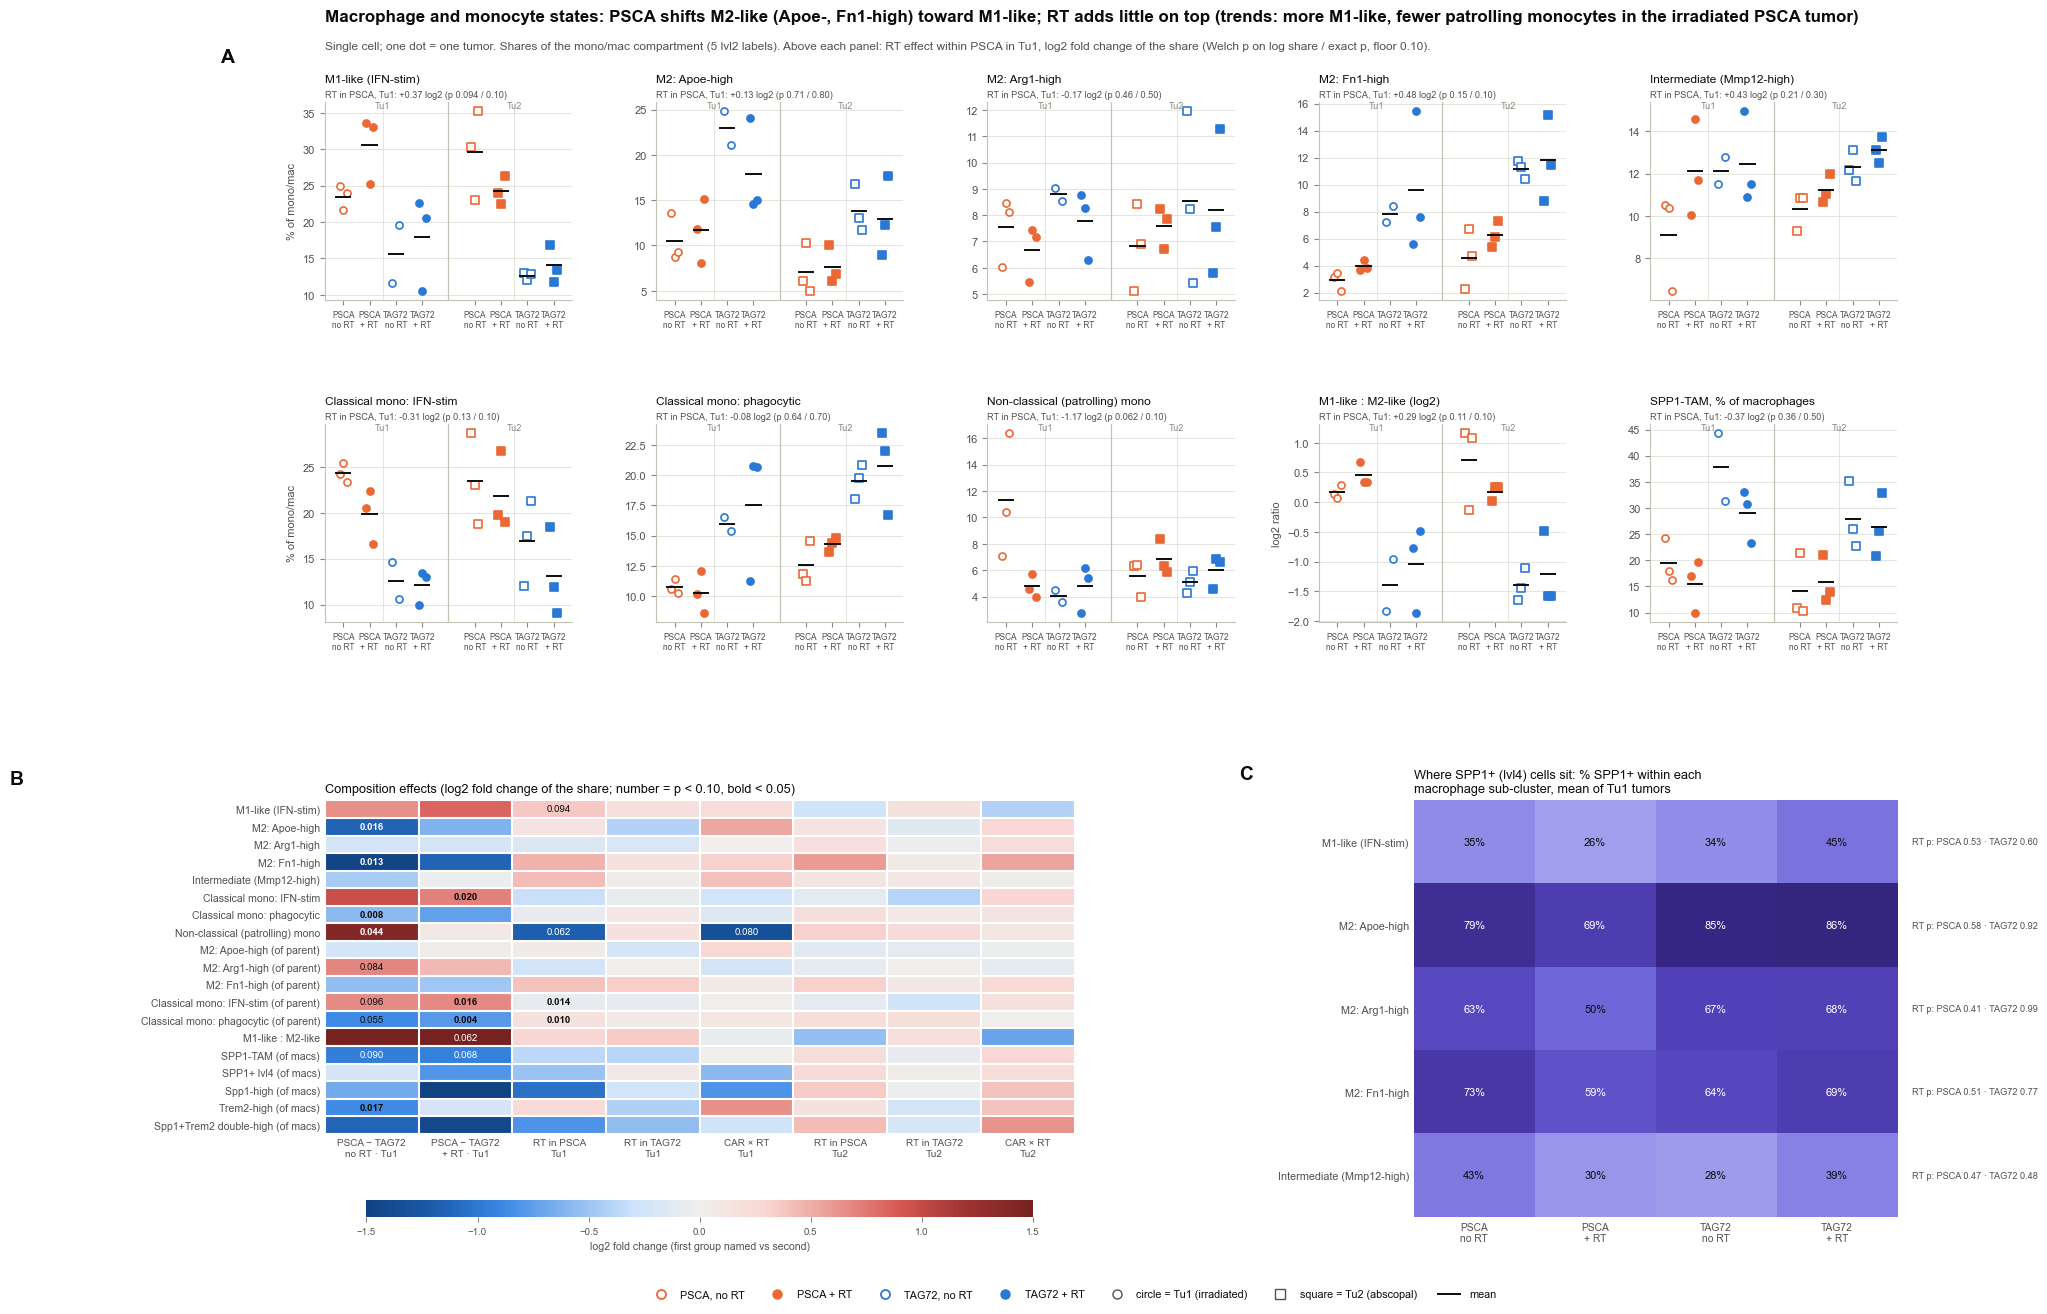

In [9]:
fig = plt.figure(figsize=(17, 13.2))
gs = GridSpec(2, 1, height_ratios=[1.25, 1.0], hspace=0.38, left=0.06, right=0.985, top=0.915, bottom=0.07)
fig.suptitle("Macrophage and monocyte states: PSCA shifts M2-like (Apoe-, Fn1-high) toward M1-like; RT adds little on top "
             "(trends: more M1-like, fewer patrolling monocytes in the irradiated PSCA tumor)", x=0.06, y=0.985, ha="left",
             fontsize=12.2, weight="bold")
fig.text(0.06, 0.955, "Single cell; one dot = one tumor. Shares of the mono/mac compartment (5 lvl2 labels). "
         "Above each panel: RT effect within PSCA in Tu1, log2 fold change of the share (Welch p on log share / exact p, floor 0.10).",
         fontsize=8.6, color=INK2)
grid = GridSpecFromSubplotSpec(2, 5, gs[0], wspace=0.34, hspace=0.62)
PANEL_FEATS = [(s, "% of mono/mac") for s, _, _, _ in SUBS] + [("log2 M1:M2", "ratio"), ("SPP1_TAM", "% of macrophages")]
PANEL_FEATS = PANEL_FEATS[:10]
for k, (feat, den) in enumerate(PANEL_FEATS):
    ax = fig.add_subplot(grid[k // 5, k % 5])
    col = f"{feat} | {den}"
    title = SUB_NAME.get(feat, {"log2 M1:M2": "M1-like : M2-like (log2)", "SPP1_TAM": "SPP1-TAM, % of macrophages"}.get(feat, feat))
    est, pw, pe = cget(feat, den, "RT Tu1", "PSCA", "est"), cget(feat, den, "RT Tu1", "PSCA", "welch"), cget(feat, den, "RT Tu1", "PSCA", "p")
    strip_sites(ax, FEAT[col], meta_s, title, ylab=("% of mono/mac" if k % 5 == 0 and den != "ratio" else ("log2 ratio" if den == "ratio" else None)),
                annot=f"RT in PSCA, Tu1: {est:+.2f} log2 (p {fmt_p(pw)} / {fmt_p(pe)})")
    if k == 0: ax.text(-0.42, 1.2, "A", transform=ax.transAxes, fontsize=14, weight="bold")

# B: effect heatmap
bot = GridSpecFromSubplotSpec(1, 2, gs[1], width_ratios=[1.55, 1.0], wspace=0.55)
COLS_B = [("PSCA Tu1", "no RT", "PSCA − TAG72\nno RT · Tu1"), ("PSCA Tu1", "RT", "PSCA − TAG72\n+ RT · Tu1"),
          ("RT Tu1", "PSCA", "RT in PSCA\nTu1"), ("RT Tu1", "TAG72", "RT in TAG72\nTu1"), ("RT Tu1", "CARxRT", "CAR × RT\nTu1"),
          ("RT Tu2", "PSCA", "RT in PSCA\nTu2"), ("RT Tu2", "TAG72", "RT in TAG72\nTu2"), ("RT Tu2", "CARxRT", "CAR × RT\nTu2")]
ROWS_B = [(s, "% of mono/mac", SUB_NAME[s]) for s, _, _, _ in SUBS] + \
         [(s, "% of parent", SUB_NAME[s] + " (of parent)") for s in ["Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac",
                                                                    "IFN_stimulated_Mono", "Phagocytic_Mono"]] + \
         [("log2 M1:M2", "ratio", "M1-like : M2-like"), ("SPP1_TAM", "% of macrophages", "SPP1-TAM (of macs)"),
          ("SPP1_alice", "% of macrophages", "SPP1+ lvl4 (of macs)"),
          ("Spp1_high", "% of macrophages", "Spp1-high (of macs)"), ("Trem2_high", "% of macrophages", "Trem2-high (of macs)"),
          ("Spp1_Trem2_high", "% of macrophages", "Spp1+Trem2 double-high (of macs)")]
MB = pd.DataFrame([[cget(f, d, e, p_, "est") for e, p_, _ in COLS_B] for f, d, _ in ROWS_B], index=[r for _, _, r in ROWS_B],
                  columns=[c for _, _, c in COLS_B])
PBm = pd.DataFrame([[cget(f, d, e, p_, "p_use") for e, p_, _ in COLS_B] for f, d, _ in ROWS_B], index=MB.index, columns=MB.columns)
ax = fig.add_subplot(bot[0]); ax.text(-0.42, 1.05, "B", transform=ax.transAxes, fontsize=14, weight="bold")
im = heat(ax, MB, PBm, vmax=1.5, p_show=0.10)
ax.set_title("Composition effects (log2 fold change of the share; number = p < 0.10, bold < 0.05)", loc="left", fontsize=9.2)
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.04, pad=0.16, aspect=40)
cb.set_label("log2 fold change (first group named vs second)", fontsize=7.6, color=INK2); cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=7)
MB.join(PBm, rsuffix=" p").to_csv(OUT/"figM1_composition_effects_matrix.csv")

# C: SPP1+ share inside each macrophage sub-cluster, mean by arm, Tu1
ax = fig.add_subplot(bot[1]); ax.text(-0.36, 1.05, "C", transform=ax.transAxes, fontsize=14, weight="bold")
SP = pd.DataFrame({SUB_NAME[s]: FEAT[FEAT.site == 1].groupby("arm")[f"SPP1+ in {s} | % of sub-cluster"].mean().reindex(ARMS4)
                   for s in MAC_SUBS}).T
SPP = pd.DataFrame({SUB_NAME[s]: [cget(f"SPP1+ in {s}", "% of sub-cluster", "RT Tu1", "PSCA", "p_use"),
                                  cget(f"SPP1+ in {s}", "% of sub-cluster", "RT Tu1", "TAG72", "p_use")] for s in MAC_SUBS},
                   index=["RT in PSCA", "RT in TAG72"]).T
seq = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba", "#382887", "#231859"])
im2 = ax.imshow(SP.values, cmap=seq, vmin=0, vmax=100, aspect="auto")
for i in range(SP.shape[0]):
    for j in range(SP.shape[1]):
        ax.text(j, i, f"{SP.iat[i, j]:.0f}%", ha="center", va="center", fontsize=8, color="white" if SP.iat[i, j] > 55 else INK)
ax.set_xticks(range(4)); ax.set_xticklabels([ARM_LAB[a] for a in ARMS4], fontsize=7.4)
ax.set_yticks(range(len(SP))); ax.set_yticklabels(SP.index, fontsize=7.8)
for i, r in enumerate(SPP.itertuples()):
    ax.text(3.62, i, f"RT p: PSCA {fmt_p(r[1])} · TAG72 {fmt_p(r[2])}", fontsize=6.6, va="center", color=INK2)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Where SPP1+ (lvl4) cells sit: % SPP1+ within each\nmacrophage sub-cluster, mean of Tu1 tumors", loc="left", fontsize=9.2)
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM1_composition.{ext}", bbox_inches="tight")
plt.show()

## 8b. Spp1-high and Trem2-high macrophages: do they shrink with PSCA, alongside Apoe-high?
* **High** = at or above one global cut: the top quartile of log1p(CP10k) over all treated-tumor macrophages.
* **Hosts:** which sub-clusters hold the high cells.
* **Decomposition:** a drop in the high share can mean fewer cells of the high-expressing sub-clusters
  (**composition**), or less Spp1/Trem2 in the same sub-clusters (**state**). For each tumor:
  - the **composition-only** share uses that tumor's sub-cluster mix with the pooled within-cluster high
    fractions;
  - the **state** part is the actual share minus the composition-only share.
  Both parts get their own exact relabelling p.
* **Per-cell expression:** pseudobulk log2 CPM of Spp1, Trem2 and Apoe within each sub-cluster.

Where the high cells sit (% of high cells, treated tumors):
                   Spp1_high       Trem2_high       Spp1_Trem2_high      
                        PSCA TAG72       PSCA TAG72            PSCA TAG72
ct3                                                                      
IFN_stimulated_Mac       9.4   5.8       16.2   7.0             2.3   1.4
Apoe_high_Mac           46.1  52.6       43.2  54.2            65.5  70.1
Arg1_high_Mac           20.1  16.9       20.0  15.9            18.5  15.1
Fn1_high_Mac            16.7  19.0        9.9  15.0            11.1  11.2
Mmp12_high_Mac           7.7   5.7       10.8   7.9             2.6   2.2

% of each sub-cluster that is high:
                    Spp1_high  Trem2_high  Spp1_Trem2_high
ct3                                                       
IFN_stimulated_Mac        5.1         7.6              0.6
Apoe_high_Mac            56.9        56.5             37.6
Arg1_high_Mac            35.8        34.7             15.6
Fn1_high_Mac    


PSCA − TAG72 per-cell expression (log2 CPM, pooled over RT strata):
                         est                                                                                    p                                                                       
group          Apoe_high_Mac Arg1_high_Mac Fn1_high_Mac IFN_stimulated_Mac Intermediate_Mac mac_all Apoe_high_Mac Arg1_high_Mac Fn1_high_Mac IFN_stimulated_Mac Intermediate_Mac mac_all
gene  effect                                                                                                                                                                            
Apoe  PSCA Tu1         -0.38         -0.44        -0.47              -1.59            -0.46   -0.95          0.40          0.28         0.24               0.00             0.44    0.03
      PSCA Tu2         -0.15          0.21        -0.20              -0.77            -0.25   -0.78          0.62          0.32         0.55               0.08             0.57    0.02
Spp1  

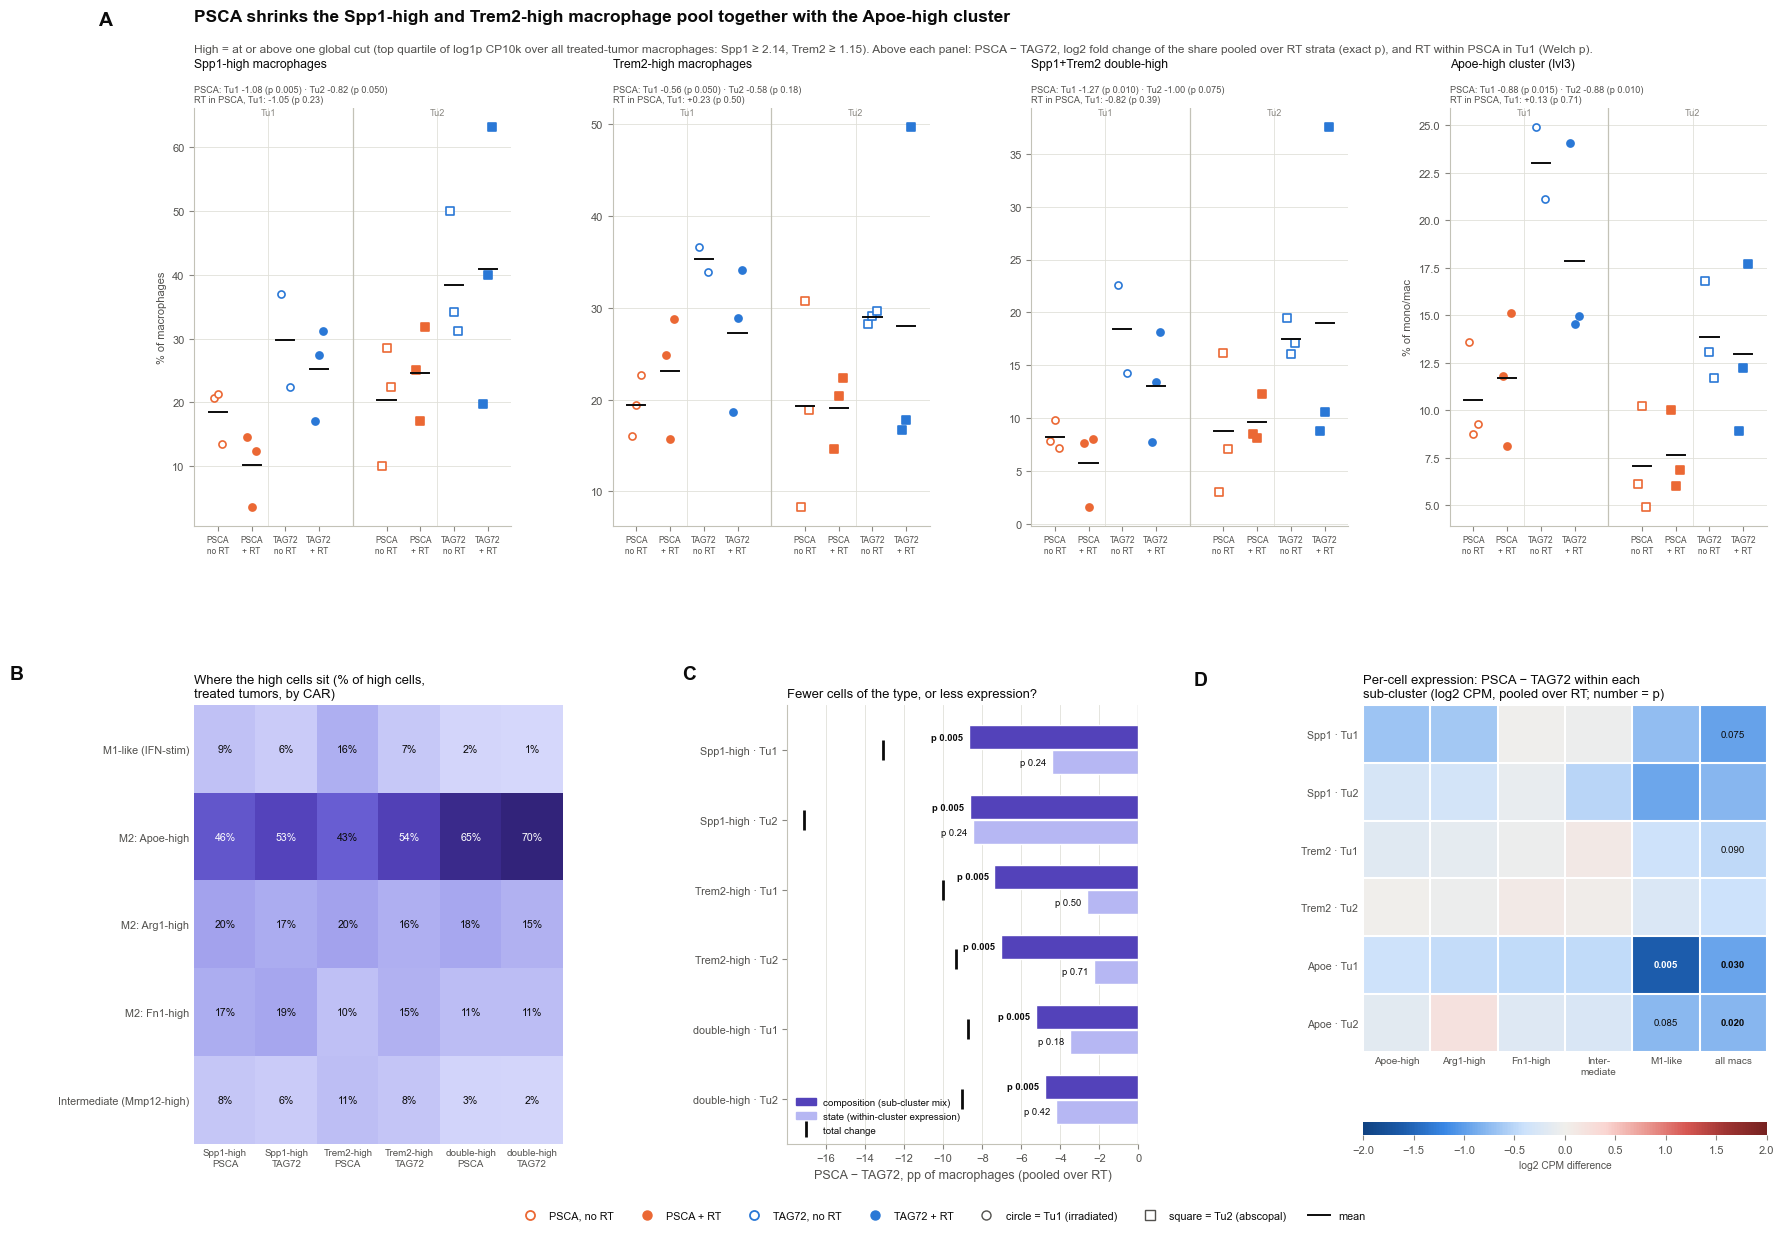

In [10]:
tr_cells = macg[macg.arm != "NoTx"]
HOST = {}
for h in ["Spp1_high", "Trem2_high", "Spp1_Trem2_high"]:
    for car, arms in [("PSCA", ["CyPSCA", "RTCyPSCA"]), ("TAG72", ["CyT72", "RTCyT72"])]:
        d = tr_cells[tr_cells.arm.isin(arms) & tr_cells[h]]
        HOST[(h, car)] = d.ct3.value_counts(normalize=True).reindex(MAC_SUBS).fillna(0) * 100
HOST = pd.DataFrame(HOST)
WITHIN = pd.DataFrame({h: tr_cells.groupby("ct3")[h].mean().reindex(MAC_SUBS) * 100 for h in ["Spp1_high", "Trem2_high", "Spp1_Trem2_high"]})
HOST.to_csv(OUT/"high_cells_host_subclusters.csv"); WITHIN.to_csv(OUT/"high_cells_within_subcluster.csv")
print("Where the high cells sit (% of high cells, treated tumors):"); print(HOST.round(1).to_string())
print("\n% of each sub-cluster that is high:"); print(WITHIN.round(1).to_string())

# per-tumor decomposition
wc = (macg.groupby(["sample", "ct3"]).size().unstack(fill_value=0).reindex(columns=MAC_SUBS).fillna(0))
wc = wc.div(wc.sum(1), axis=0)
dec_rows = []
DEC = {}
for h in ["Spp1_high", "Trem2_high", "Spp1_Trem2_high"]:
    fbar = tr_cells.groupby("ct3")[h].mean().reindex(MAC_SUBS)
    actual = macg.groupby("sample")[h].mean() * 100
    comp_only = (wc[MAC_SUBS] * fbar).sum(1) * 100
    state = actual - comp_only.reindex(actual.index)
    DEC[h] = pd.DataFrame({"actual": actual, "composition_only": comp_only.reindex(actual.index), "state_residual": state})
    for part_name, v in DEC[h].items():
        for eff in ["PSCA Tu1", "PSCA Tu2", "RT Tu1", "RT Tu2"]:
            for part, d in effect(v, meta_s, eff).items():
                dec_rows.append(dict(high=h, component=part_name, effect=eff, part=part, est_pp=d["est"], p=d["p"], welch=d["welch"]))
DECE = pd.DataFrame(dec_rows); DECE["p_use"] = DECE.apply(lambda r: best_p(r), axis=1)
DECE.to_csv(OUT/"high_cells_decomposition.csv", index=False)
print("\nPSCA − TAG72 (pooled over RT strata), percentage points of macrophages:")
print(DECE[DECE.part == "pooled"].pivot_table(index=["high", "component"], columns="effect", values=["est_pp", "p"]).round(3).to_string())

# per-cell expression (pseudobulk) within each sub-cluster and in all macrophages
EXP_GROUPS = ["Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Intermediate_Mac", "IFN_stimulated_Mac", "mac_all"]
erows = []
for g in EXP_GROUPS:
    d = PBM[(PBM.group == g) & (PBM.n_cells >= MIN_CELLS)]
    em = d.set_index("sample")[["arm", "site"]]
    for gene in HIGH_GENES:
        v = pd.Series(L.loc[d.index, gene].values, index=d["sample"].values)
        erows += effect_rows(v, em, group=g, gene=gene)
EXPE = pd.DataFrame(erows); EXPE["p_use"] = EXPE.apply(best_p, axis=1)
EXPE.to_csv(OUT/"high_genes_expression_effects.csv", index=False)
print("\nPSCA − TAG72 per-cell expression (log2 CPM, pooled over RT strata):")
print(EXPE[(EXPE.part == "pooled") & EXPE.effect.str.startswith("PSCA")]
      .pivot_table(index=["gene", "effect"], columns="group", values=["est", "p"]).round(2).to_string())

# ---- Figure M1b ----
fig = plt.figure(figsize=(17, 12.4))
gs = GridSpec(2, 1, height_ratios=[1.0, 1.05], hspace=0.42, left=0.06, right=0.985, top=0.905, bottom=0.07)
fig.suptitle("PSCA shrinks the Spp1-high and Trem2-high macrophage pool together with the Apoe-high cluster",
             x=0.06, y=0.985, ha="left", fontsize=12.5, weight="bold")
fig.text(0.06, 0.95, f"High = at or above one global cut (top quartile of log1p CP10k over all treated-tumor macrophages: "
         f"Spp1 ≥ {HIGH_CUT['Spp1']:.2f}, Trem2 ≥ {HIGH_CUT['Trem2']:.2f}). Above each panel: PSCA − TAG72, log2 fold "
         "change of the share pooled over RT strata (exact p), and RT within PSCA in Tu1 (Welch p).", fontsize=8.6, color=INK2)
top = GridSpecFromSubplotSpec(1, 4, gs[0], wspace=0.32)
for k, (feat, den, title) in enumerate([("Spp1_high", "% of macrophages", "Spp1-high macrophages"),
                                        ("Trem2_high", "% of macrophages", "Trem2-high macrophages"),
                                        ("Spp1_Trem2_high", "% of macrophages", "Spp1+Trem2 double-high"),
                                        ("Apoe_high_Mac", "% of mono/mac", "Apoe-high cluster (lvl3)")]):
    ax = fig.add_subplot(top[k])
    e1, p1 = cget(feat, den, "PSCA Tu1", "pooled", "est"), cget(feat, den, "PSCA Tu1", "pooled", "p")
    e2, p2 = cget(feat, den, "PSCA Tu2", "pooled", "est"), cget(feat, den, "PSCA Tu2", "pooled", "p")
    er, pr = cget(feat, den, "RT Tu1", "PSCA", "est"), cget(feat, den, "RT Tu1", "PSCA", "welch")
    strip_sites(ax, FEAT[f"{feat} | {den}"], meta_s, title, ylab=den if k in (0, 3) else None,
                annot=f"PSCA: Tu1 {e1:+.2f} (p {fmt_p(p1)}) · Tu2 {e2:+.2f} (p {fmt_p(p2)})\nRT in PSCA, Tu1: {er:+.2f} (p {fmt_p(pr)})")
    ax.set_title(title, loc="left", fontsize=8.8, pad=30)
    if k == 0: ax.text(-0.3, 1.2, "A", transform=ax.transAxes, fontsize=14, weight="bold")

bot = GridSpecFromSubplotSpec(1, 3, gs[1], width_ratios=[1.05, 1.0, 1.15], wspace=0.6)
ax = fig.add_subplot(bot[0]); ax.text(-0.5, 1.06, "B", transform=ax.transAxes, fontsize=14, weight="bold")
seq = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba", "#382887", "#231859"])
H_ = HOST.copy(); H_.columns = [f"{ {'Spp1_high': 'Spp1-high', 'Trem2_high': 'Trem2-high', 'Spp1_Trem2_high': 'double-high'}[h]}\n{c}" for h, c in H_.columns]
ax.imshow(H_.values, cmap=seq, vmin=0, vmax=80, aspect="auto")
for i in range(H_.shape[0]):
    for j in range(H_.shape[1]):
        ax.text(j, i, f"{H_.iat[i, j]:.0f}%", ha="center", va="center", fontsize=7.6, color="white" if H_.iat[i, j] > 45 else INK)
ax.set_xticks(range(H_.shape[1])); ax.set_xticklabels(H_.columns, fontsize=7)
ax.set_yticks(range(len(MAC_SUBS))); ax.set_yticklabels([SUB_NAME[s] for s in MAC_SUBS], fontsize=7.8)
ax.tick_params(length=0); [sp_.set_visible(False) for sp_ in ax.spines.values()]
ax.set_title("Where the high cells sit (% of high cells,\ntreated tumors, by CAR)", loc="left", fontsize=9.4)

ax = fig.add_subplot(bot[1]); ax.text(-0.3, 1.06, "C", transform=ax.transAxes, fontsize=14, weight="bold")
labs, yv = [], 0
for h, hl in [("Spp1_high", "Spp1-high"), ("Trem2_high", "Trem2-high"), ("Spp1_Trem2_high", "double-high")]:
    for eff, el in [("PSCA Tu1", "Tu1"), ("PSCA Tu2", "Tu2")]:
        d = DECE[(DECE.high == h) & (DECE.effect == eff) & (DECE.part == "pooled")].set_index("component")
        c_, s_ = d.loc["composition_only"], d.loc["state_residual"]
        ax.barh(yv + 0.18, c_.est_pp, height=0.34, color="#5342ba", edgecolor="white")
        ax.barh(yv - 0.18, s_.est_pp, height=0.34, color="#b6b7f3", edgecolor="white")
        for val, yy_, pp in [(c_.est_pp, yv + 0.18, c_.p), (s_.est_pp, yv - 0.18, s_.p)]:
            ax.text(val + (0.3 if val >= 0 else -0.3), yy_, f"p {fmt_p(pp)}", va="center", ha="left" if val >= 0 else "right",
                    fontsize=6.8, color=INK, weight="bold" if pp < 0.05 else "normal")
        tot = d.loc["actual"]
        ax.plot(tot.est_pp, yv, marker="|", ms=14, mew=2, color=INK)
        labs.append((yv, f"{hl} · {el}")); yv -= 1
ax.set_yticks([y_ for y_, _ in labs]); ax.set_yticklabels([l for _, l in labs], fontsize=7.8)
ax.axvline(0, color=INK2, lw=0.8); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("PSCA − TAG72, pp of macrophages (pooled over RT)")
ax.set_title("Fewer cells of the type, or less expression?", loc="left", fontsize=9.4)
ax.legend(handles=[mpl.patches.Patch(color="#5342ba", label="composition (sub-cluster mix)"),
                   mpl.patches.Patch(color="#b6b7f3", label="state (within-cluster expression)"),
                   Line2D([], [], marker="|", ls="", ms=12, mew=2, color=INK, label="total change")],
          loc="lower left", frameon=False, fontsize=7)

ax = fig.add_subplot(bot[2]); ax.text(-0.42, 1.06, "D", transform=ax.transAxes, fontsize=14, weight="bold")
EG = ["Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Intermediate_Mac", "IFN_stimulated_Mac", "mac_all"]
EGL = {"Apoe_high_Mac": "Apoe-high", "Arg1_high_Mac": "Arg1-high", "Fn1_high_Mac": "Fn1-high", "Intermediate_Mac": "Inter-\nmediate",
       "IFN_stimulated_Mac": "M1-like", "mac_all": "all macs"}
rows_d = [(g_, e_) for g_ in HIGH_GENES for e_ in ["PSCA Tu1", "PSCA Tu2"]]
ME = pd.DataFrame([[EXPE[(EXPE.gene == g_) & (EXPE.effect == e_) & (EXPE.part == "pooled") & (EXPE.group == grp)].est.squeeze()
                    for grp in EG] for g_, e_ in rows_d], index=[f"{g_} · {e_[-3:]}" for g_, e_ in rows_d], columns=EG).astype(float)
MP = pd.DataFrame([[EXPE[(EXPE.gene == g_) & (EXPE.effect == e_) & (EXPE.part == "pooled") & (EXPE.group == grp)].p.squeeze()
                    for grp in EG] for g_, e_ in rows_d], index=ME.index, columns=EG).astype(float)
im = heat(ax, ME, MP, vmax=2.0, p_show=0.10, col_labels=[EGL[g] for g in EG], fs=7)
ax.set_title("Per-cell expression: PSCA − TAG72 within each\nsub-cluster (log2 CPM, pooled over RT; number = p)", loc="left", fontsize=9.4)
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.16, aspect=30)
cb.set_label("log2 CPM difference", fontsize=7.4, color=INK2); cb.outline.set_visible(False)
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM1b_spp1_trem2_high.{ext}", bbox_inches="tight")
plt.show()

## 8c. Check: a shared immediate-early / NF-κB program moves with CAR × RT
The strongest CAR × RT signals in the irradiated tumor are NF-κB and immediate-early genes (Hallmark TNFα/NF-κB,
Nr4a1/3, Il1b, Cd80/Cd86, Pvr). These genes also respond to tissue dissociation and handling. Three questions:
1. Does an immediate-early (IEG) score shift with CAR × RT in **every** compartment of the same tumor? If so, the
   driver is shared by the whole tumor: technical (handling) or systemic. These data cannot tell which.
2. Is the score coherent within a mouse, i.e. does Tu1 track Tu2?
3. Which focus genes keep their CAR × RT effect after adjusting for the score? Which co-vary with it from tumor
   to tumor **within** an arm (within-arm r)?
Adjustment is conservative: the score is nearly collinear with the arms, so it also removes real signal.

IEG score: 31 genes. CAR x RT per compartment:
                      est             p       
effect             RT Tu1 RT Tu2 RT Tu1 RT Tu2
group                                         
CD8_T               -2.13    NaN   0.07    NaN
Cancer_cell         -0.32   0.31   0.66   0.55
Classical_Mono      -1.97  -1.42   0.14   0.08
IFN_stimulated_Mac  -2.00  -1.40   0.14   0.07
Intermediate_Mac    -2.05  -1.45   0.12   0.06
M2_like_Mac         -2.18  -1.23   0.12   0.16
N1_like_Neu         -0.70  -1.04   0.43   0.28
NK                  -0.93    NaN   0.45    NaN
Nonclassical_Mono   -1.75  -0.77   0.22   0.26
SPP1_TAM            -2.07  -1.30   0.12   0.15
cDC                 -1.15  -0.73   0.37   0.36
same-mouse Tu1 vs Tu2 IEG (all macrophages): rho 0.35 (p 0.285), arm-centered rho 0.18 (p 0.593), n mice 11
             group  gene  carxrt    p  carxrt_adj  p_adj  kept  within_arm_r
IFN_stimulated_Mac Ciita    1.02 0.24       -0.15   0.64 -0.15         -0.98
IFN_stimulated_Mac   Pvr   -1.47 


Hallmark CAR x RT (Tu1): number of the 8 myeloid groups at FDR < 0.05 and mean NES, all genes vs IEG genes removed
                                             n_fdr05                    mean_NES          
ranking                            IEG genes removed all genes IEG genes removed all genes
pathway                                                                                   
HALLMARK_APOPTOSIS                                 8         8             -1.91     -1.99
HALLMARK_CHOLESTEROL_HOMEOSTASIS                   7         7             -1.80     -1.82
HALLMARK_G2M_CHECKPOINT                            8         8             -2.36     -2.34
HALLMARK_HYPOXIA                                   8         8             -1.81     -1.93
HALLMARK_INFLAMMATORY_RESPONSE                     8         8             -2.00     -2.04
HALLMARK_INTERFERON_GAMMA_RESPONSE                 2         2             -0.91     -0.94
HALLMARK_MTORC1_SIGNALING                          8         8   

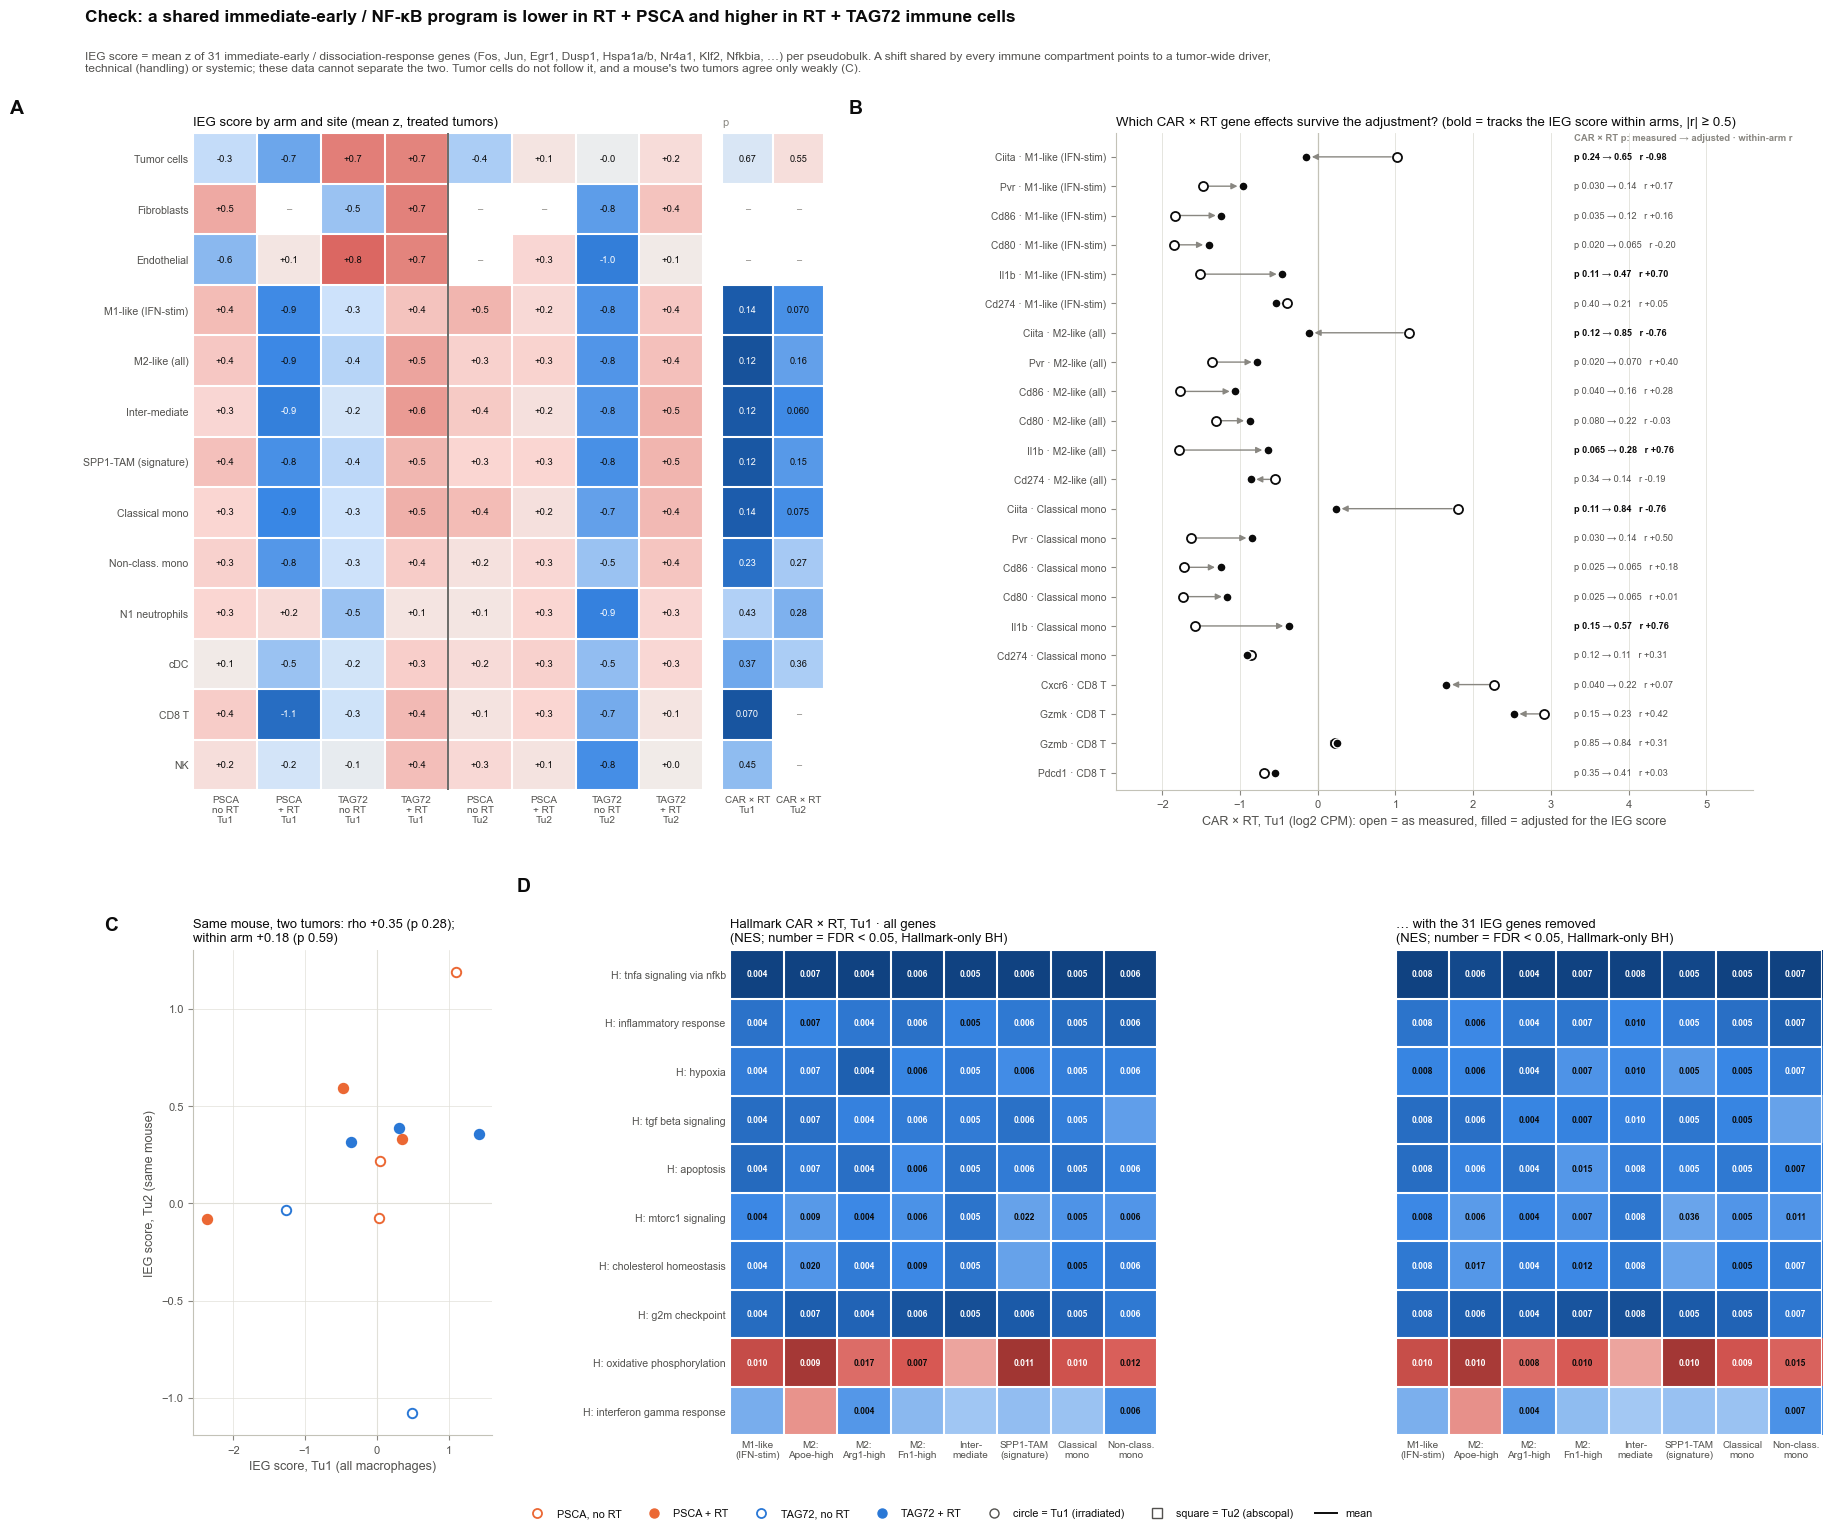

In [11]:
IEG_GENES = [g for g in ["Fos", "Fosb", "Jun", "Junb", "Jund", "Egr1", "Egr2", "Egr3", "Atf3", "Ier2", "Ier3", "Ier5", "Dusp1",
                         "Hspa1a", "Hspa1b", "Hspa8", "Hsp90aa1", "Hspb1", "Nr4a1", "Nr4a2", "Zfp36", "Klf2", "Klf4", "Klf6",
                         "Socs3", "Nfkbia", "Ppp1r15a", "Btg2", "Cebpd", "Gadd45b", "Ccn1", "Cyr61", "Rhob"] if g in L.columns]
COMPS = ["Cancer_cell", "Fibroblast", "Endothelial", "IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM",
         "Classical_Mono", "Nonclassical_Mono", "N1_like_Neu", "cDC", "CD8_T", "NK"]
COMP_LAB = {"Cancer_cell": "Tumor cells", "Fibroblast": "Fibroblasts", "Endothelial": "Endothelial", "N1_like_Neu": "N1 neutrophils",
            "cDC": "cDC", "CD8_T": "CD8 T", "NK": "NK", **{k: flat(v) for k, v in BEH.items()}}


def ieg_score(group):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS) & (PBM.arm != "NoTx")]
    if len(d) < 6: return None, None
    Lg = L.loc[d.index]; ex = [g for g in IEG_GENES if Lg[g].mean() >= 1]
    sc = ((Lg[ex] - Lg[ex].mean()) / Lg[ex].std()).mean(1); sc.index = d["sample"].values
    return sc, d.set_index("sample")[["arm", "site"]]


IEGS, irow = {}, []
for g in COMPS:
    sc, m = ieg_score(g)
    if sc is None: continue
    IEGS[g] = (sc, m)
    for eff in ["RT Tu1", "RT Tu2"]:
        for part, d in effect(sc, m, eff).items():
            irow.append(dict(group=g, effect=eff, part=part, est=d["est"], p=d["p"], welch=d["welch"]))
IEGE = pd.DataFrame(irow); IEGE["p_use"] = IEGE.apply(best_p, axis=1)
IEGE.to_csv(OUT/"ieg_axis_effects.csv", index=False)
IEGM = pd.DataFrame({g: sc.groupby([m.arm, m.site]).mean() for g, (sc, m) in IEGS.items()}).T
print(f"IEG score: {len(IEG_GENES)} genes. CAR x RT per compartment:")
print(IEGE[IEGE.part == "CARxRT"].pivot(index="group", columns="effect", values=["est", "p"]).round(2).to_string())

# same-mouse coherence (Tu1 vs Tu2 of one mouse), all macrophages
sc_m, m_m = ieg_score("mac_all")
mouse = pd.Series([f"{a}_{s_.rsplit('_', 1)[1]}" for a, s_ in zip(m_m.arm, sc_m.index)], index=sc_m.index)
pair = pd.DataFrame({"score": sc_m, "mouse": mouse, "site": m_m.site, "arm": m_m.arm}).pivot_table(index=["mouse", "arm"], columns="site", values="score").dropna()
pair_r = stats.spearmanr(pair[1], pair[2])
pc_ = pair.sub(pair.groupby(level="arm").transform("mean"))
pair_rc = stats.spearmanr(pc_[1], pc_[2])
print(f"same-mouse Tu1 vs Tu2 IEG (all macrophages): rho {pair_r.correlation:.2f} (p {pair_r.pvalue:.3f}), "
      f"arm-centered rho {pair_rc.correlation:.2f} (p {pair_rc.pvalue:.3f}), n mice {len(pair)}")

# adjusted vs unadjusted CAR x RT for focus genes (Tu1), and within-arm correlation with the IEG score
ADJ_SET = {"IFN_stimulated_Mac": ["Ciita", "Pvr", "Cd86", "Cd80", "Il1b", "Cd274"],
           "M2_like_Mac": ["Ciita", "Pvr", "Cd86", "Cd80", "Il1b", "Cd274"],
           "Classical_Mono": ["Ciita", "Pvr", "Cd86", "Cd80", "Il1b", "Cd274"],
           "CD8_T": ["Cxcr6", "Gzmk", "Gzmb", "Pdcd1"]}
arow = []
for g, genes in ADJ_SET.items():
    d = PBM[(PBM.group == g) & (PBM.n_cells >= MIN_CELLS) & (PBM.site == 1) & PBM.arm.isin(ARMS4)]
    sc = IEGS[g][0].reindex(d["sample"].values).values
    mt = d.set_index("sample")[["arm", "site"]]
    for gene in genes:
        if gene not in L.columns: continue
        y = pd.Series(L.loc[d.index, gene].values, index=mt.index)
        b_ = np.polyfit(sc, y.values, 1); r_ = y - np.polyval(b_, sc)
        e0 = effect(y, mt, "RT Tu1")["CARxRT"]; e1 = effect(r_, mt, "RT Tu1")["CARxRT"]
        yc = y - y.groupby(mt.arm).transform("mean"); scc = pd.Series(sc, index=mt.index); scc = scc - scc.groupby(mt.arm).transform("mean")
        arow.append(dict(group=g, gene=gene, carxrt=e0["est"], p=e0["p"], carxrt_adj=e1["est"], p_adj=e1["p"],
                         kept=e1["est"] / e0["est"] if e0["est"] else np.nan, within_arm_r=float(np.corrcoef(yc, scc)[0, 1])))
ADJ = pd.DataFrame(arow); ADJ.to_csv(OUT/"ieg_adjusted_carxrt_tu1.csv", index=False)
print(ADJ.round(2).to_string(index=False))

# within-arm correlation of every module score with the IEG score of the same group, per site (for the scorecard flag)
frow = []
for g in FIT_GROUPS:
    if g not in IEGS:
        sc, m = ieg_score(g); IEGS[g] = (sc, m)
    sc, m = IEGS[g]; S, meta = SCORES[g]
    for site in (1, 2):
        idx = [i for i in S.index if i in sc.index and meta.loc[i, "site"] == site and meta.loc[i, "arm"] in ARMS4]
        if len(idx) < 6: continue
        arms_ = meta.loc[idx, "arm"]; z = sc[idx]; zc = z - z.groupby(arms_).transform("mean")
        for col in S.columns:
            y = S.loc[idx, col]; yc = y - y.groupby(arms_).transform("mean")
            frow.append(dict(group=g, module=col, site=site, ieg_r=float(np.corrcoef(yc, zc)[0, 1]) if yc.std() > 0 else np.nan))
IEGR = pd.DataFrame(frow); IEGR.to_csv(OUT/"ieg_within_arm_r_modules.csv", index=False)

# Hallmark GSEA for the RT contrasts at Tu1, with and without the IEG genes in the ranking (Hallmark-only collection)
HALL_SETS = {k: v for k, v in GMT.items() if k.startswith("HALLMARK_")}
NOIEG_CACHE = OUT/"gsea_hallmark_with_without_ieg.parquet"
if NOIEG_CACHE.exists():
    GSN = pd.read_parquet(NOIEG_CACHE)
else:
    res = []
    for (g, c), d in DS[(DS.site == 1) & DS.contrast.isin(["RT_in_PSCA", "RT_in_TAG72", "CARxRT"]) & DS.group.isin(M3_GROUPS_)].groupby(["group", "contrast"]):
        rk = d.set_index("gene")["stat"]
        res.append(gsea_prerank(rk, HALL_SETS).assign(group=g, contrast=c, ranking="all genes"))
        res.append(gsea_prerank(rk.drop(IEG_GENES, errors="ignore"), HALL_SETS).assign(group=g, contrast=c, ranking="IEG genes removed"))
    GSN = pd.concat(res, ignore_index=True); GSN.to_parquet(NOIEG_CACHE)
KEYH = ["HALLMARK_TNFA_SIGNALING_VIA_NFKB", "HALLMARK_INFLAMMATORY_RESPONSE", "HALLMARK_HYPOXIA", "HALLMARK_TGF_BETA_SIGNALING",
        "HALLMARK_APOPTOSIS", "HALLMARK_MTORC1_SIGNALING", "HALLMARK_CHOLESTEROL_HOMEOSTASIS", "HALLMARK_G2M_CHECKPOINT",
        "HALLMARK_OXIDATIVE_PHOSPHORYLATION", "HALLMARK_INTERFERON_GAMMA_RESPONSE"]
print("\nHallmark CAR x RT (Tu1): number of the 8 myeloid groups at FDR < 0.05 and mean NES, all genes vs IEG genes removed")
_t = GSN[(GSN.contrast == "CARxRT") & GSN.pathway.isin(KEYH)]
print(_t.groupby(["pathway", "ranking"]).agg(n_fdr05=("FDR", lambda x: int((x < 0.05).sum())), mean_NES=("NES", "mean"))
      .unstack("ranking").round(2).to_string())
GSN.to_csv(OUT/"gsea_hallmark_with_without_ieg.csv", index=False)

# genes behind the two strongest 'advantage' modules
DRV = DS[(DS.site == 1) & DS.contrast.isin(["RT_in_PSCA", "RT_in_TAG72", "CARxRT"]) &
         DS.gene.isin(MODULES["Adenosine axis"][1] + MODULES["Suppressive mediators"][1]) &
         DS.group.isin(["Classical_Mono", "IFN_stimulated_Mono", "Nonclassical_Mono", "M2_like_Mac", "SPP1_TAM", "Intermediate_Mac", "IFN_stimulated_Mac"])]
DRV = DRV[["group", "gene", "contrast", "log2FoldChange", "pvalue", "baseMean"]]
DRV.to_csv(OUT/"advantage_module_driver_genes_tu1.csv", index=False)
print("\nDriver genes (Tu1, DESeq2 log2FC; CAR x RT p < 0.05):")
_d = DRV[DRV.contrast == "CARxRT"]
print(_d[_d.pvalue < 0.05].sort_values(["gene", "group"]).round(3).to_string(index=False))

# ---- Figure M6 ----
fig = plt.figure(figsize=(18, 15.5))
gs = GridSpec(2, 1, height_ratios=[1.15, 0.85], hspace=0.28, left=0.08, right=0.985, top=0.9, bottom=0.06)
fig.suptitle("Check: a shared immediate-early / NF-κB program is lower in RT + PSCA and higher in RT + TAG72 immune cells",
             x=0.02, y=0.98, ha="left", fontsize=12.5, weight="bold")
fig.text(0.02, 0.94, f"IEG score = mean z of {len(IEG_GENES)} immediate-early / dissociation-response genes (Fos, Jun, Egr1, Dusp1, "
         "Hspa1a/b, Nr4a1, Klf2, Nfkbia, …) per pseudobulk. A shift shared by every immune compartment points to a tumor-wide "
         "driver,\ntechnical (handling) or systemic; these data cannot separate the two. Tumor cells do not follow it, and a mouse's "
         "two tumors agree only weakly (C).", fontsize=8.6, color=INK2)
top = GridSpecFromSubplotSpec(1, 5, gs[0], width_ratios=[1.0, 0.2, 0.5, 1.25, 0.1], wspace=0.06)
ax = fig.add_subplot(top[0]); ax.text(-0.36, 1.03, "A", transform=ax.transAxes, fontsize=14, weight="bold")
cols_ = [(a, s_) for s_ in (1, 2) for a in ARMS4]
MA = IEGM.reindex(columns=pd.MultiIndex.from_tuples(cols_))
MA = MA.reindex([g for g in COMPS if g in MA.index])
heat(ax, MA, None, vmax=1.5, fmt_val=lambda v: f"{v:+.1f}", fs=6.8,
     row_labels=[COMP_LAB.get(g, g) for g in MA.index], col_labels=[f"{ARM_LAB[a]}\nTu{s_}" for a, s_ in cols_])
ax.axvline(3.5, color=INK2, lw=1.2)
ax.set_title("IEG score by arm and site (mean z, treated tumors)", loc="left", fontsize=9.6)
ax = fig.add_subplot(top[1])
CX = pd.DataFrame({e: IEGE[(IEGE.part == "CARxRT") & (IEGE.effect == e)].set_index("group").est for e in ["RT Tu1", "RT Tu2"]}).reindex(MA.index)
CP = pd.DataFrame({e: IEGE[(IEGE.part == "CARxRT") & (IEGE.effect == e)].set_index("group").p for e in ["RT Tu1", "RT Tu2"]}).reindex(MA.index)
heat(ax, CX, CP, vmax=2.5, p_show=1.01, fs=6.6, row_labels=[""] * len(MA), col_labels=["CAR × RT\nTu1", "CAR × RT\nTu2"])
ax.set_title("p", loc="left", fontsize=8, color=MUTED)

ax = fig.add_subplot(top[3]); ax.text(-0.42, 1.03, "B", transform=ax.transAxes, fontsize=14, weight="bold")
labs = []
for i, r in enumerate(ADJ.itertuples()):
    y = -i
    ax.annotate("", xy=(r.carxrt_adj, y), xytext=(r.carxrt, y), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.0, shrinkA=4, shrinkB=4))
    ax.plot(r.carxrt, y, "o", mfc="white", mec=INK, mew=1.3, ms=6.5, zorder=3)
    ax.plot(r.carxrt_adj, y, "o", color=INK, ms=6.5, mec="white", zorder=4)
    ax.text(3.3, y, f"p {fmt_p(r.p)} → {fmt_p(r.p_adj)}   r {r.within_arm_r:+.2f}", fontsize=6.6, va="center",
            color=INK if abs(r.within_arm_r) >= 0.5 else INK2, weight="bold" if abs(r.within_arm_r) >= 0.5 else "normal")
    labs.append(f"{r.gene} · {COMP_LAB.get(r.group, r.group)}")
ax.axvline(0, color=AXIS, lw=0.9); ax.set_yticks([-i for i in range(len(ADJ))]); ax.set_yticklabels(labs, fontsize=7.4)
ax.set_xlim(-2.6, 5.6); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_ylim(-len(ADJ) + 0.4, 0.8)
ax.text(3.3, 0.55, "CAR × RT p: measured → adjusted · within-arm r", fontsize=6.8, color=MUTED, weight="bold")
ax.set_xlabel("CAR × RT, Tu1 (log2 CPM): open = as measured, filled = adjusted for the IEG score")
ax.set_title("Which CAR × RT gene effects survive the adjustment? (bold = tracks the IEG score within arms, |r| ≥ 0.5)",
             loc="left", fontsize=9.6)

bot = GridSpecFromSubplotSpec(1, 3, gs[1], width_ratios=[0.7, 1.0, 1.0], wspace=0.62)
ax = fig.add_subplot(bot[0]); ax.text(-0.3, 1.04, "C", transform=ax.transAxes, fontsize=14, weight="bold")
for (mid, arm), r in pair.iterrows():
    col_ = CAR_COL[CAR_OF[arm]]
    ax.scatter(r[1], r[2], s=46, facecolor=col_ if RT_OF[arm] else "white", edgecolor=col_, linewidth=1.4, zorder=3)
ax.axhline(0, color=GRID, lw=0.8); ax.axvline(0, color=GRID, lw=0.8)
ax.set_xlabel("IEG score, Tu1 (all macrophages)"); ax.set_ylabel("IEG score, Tu2 (same mouse)")
ax.set_title(f"Same mouse, two tumors: rho {pair_r.correlation:+.2f} (p {fmt_p(pair_r.pvalue)});\nwithin arm {pair_rc.correlation:+.2f} "
             f"(p {fmt_p(pair_rc.pvalue)})", loc="left", fontsize=9.4)
ax.grid(True, color=GRID, lw=0.5); ax.set_axisbelow(True)
for k, (rk_, title) in enumerate([("all genes", "Hallmark CAR × RT, Tu1 · all genes"),
                                  ("IEG genes removed", f"… with the {len(IEG_GENES)} IEG genes removed")]):
    ax = fig.add_subplot(bot[1 + k])
    d = GSN[(GSN.contrast == "CARxRT") & (GSN.ranking == rk_)]
    N_ = d.pivot(index="pathway", columns="group", values="NES").reindex(index=KEYH, columns=M3_GROUPS_)
    Q_ = d.pivot(index="pathway", columns="group", values="FDR").reindex(index=KEYH, columns=M3_GROUPS_)
    heat(ax, N_, Q_, vmax=3.0, p_show=0.05, fs=6.2, row_labels=[short(h) for h in KEYH] if k == 0 else [""] * len(KEYH),
         col_labels=[BEH[g] for g in M3_GROUPS_])
    ax.set_title(title + "\n(NES; number = FDR < 0.05, Hallmark-only BH)", loc="left", fontsize=9.4)
    if k == 0: ax.text(-0.5, 1.12, "D", transform=ax.transAxes, fontsize=14, weight="bold")
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM6_ieg_axis_check.{ext}", bbox_inches="tight")
plt.show()

## 9. Figure M2 — what each macrophage state does

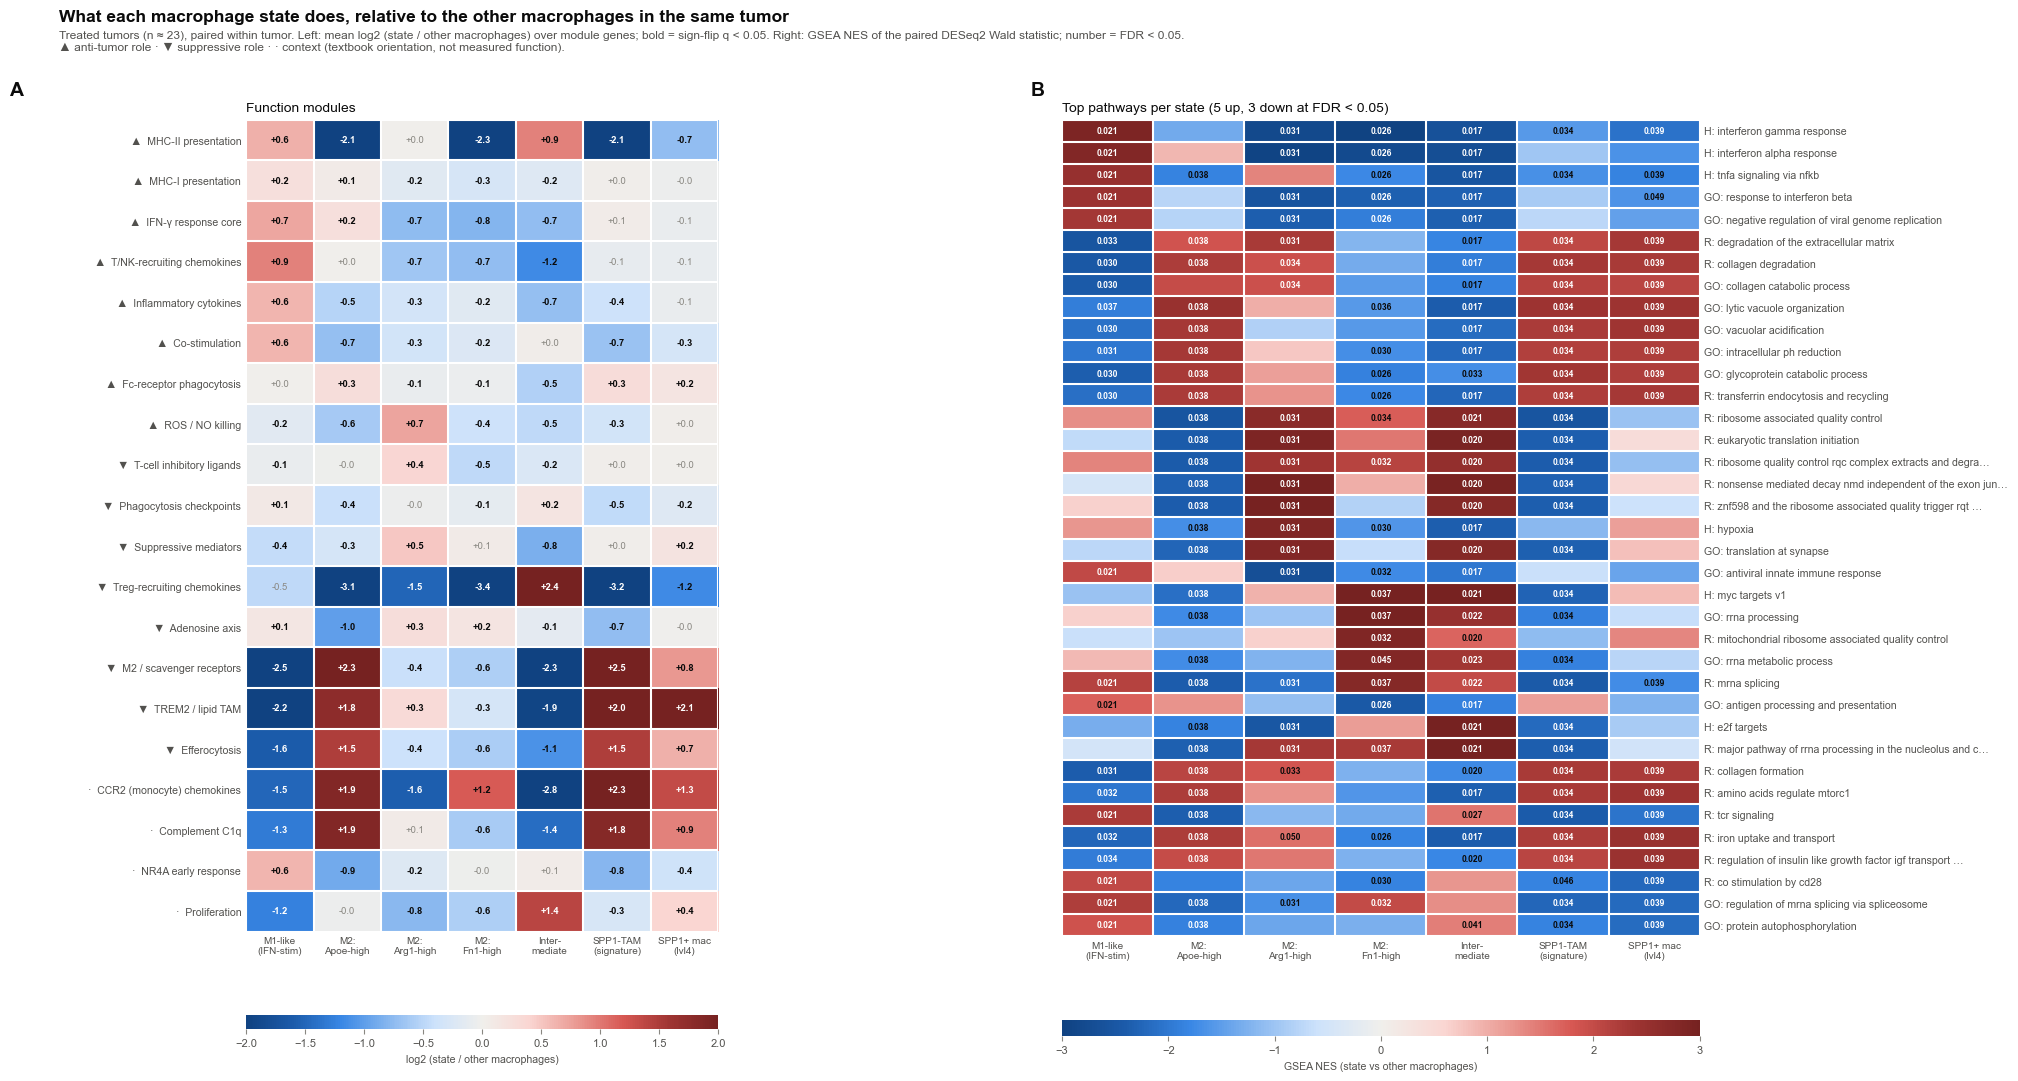

In [12]:
STATES = list(STATE_REST)
MOD_ROWS = list(MODULES)
IM = IDN.pivot(index="module", columns="state", values="mean_log2").reindex(index=MOD_ROWS, columns=STATES)
IQ = IDN.pivot(index="module", columns="state", values="q").reindex(index=MOD_ROWS, columns=STATES)
fig = plt.figure(figsize=(17, 11.6))
gs = GridSpec(1, 2, width_ratios=[1.0, 1.35], wspace=0.62, left=0.13, right=0.985, top=0.88, bottom=0.08)
fig.suptitle("What each macrophage state does, relative to the other macrophages in the same tumor",
             x=0.02, y=0.975, ha="left", fontsize=12.5, weight="bold")
fig.text(0.02, 0.94, "Treated tumors (n ≈ 23), paired within tumor. Left: mean log2 (state / other macrophages) over module genes; "
         "bold = sign-flip q < 0.05. Right: GSEA NES of the paired DESeq2 Wald statistic; number = FDR < 0.05.\n"
         "▲ anti-tumor role · ▼ suppressive role · · context (textbook orientation, not measured function).",
         fontsize=8.6, color=INK2)
ax = fig.add_subplot(gs[0]); ax.text(-0.5, 1.03, "A", transform=ax.transAxes, fontsize=14, weight="bold")
im = heat(ax, IM, None, vmax=2.0, fmt_val=lambda v: f"{v:+.1f}", row_labels=[f"{TAG[ORI[m]]}  {m}" for m in MOD_ROWS],
          col_labels=[BEH[s] for s in STATES], fs=6.8, bold=(IQ < 0.05))
ax.set_title("Function modules", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.035, pad=0.09, aspect=35)
cb.set_label("log2 (state / other macrophages)", fontsize=7.6, color=INK2); cb.outline.set_visible(False)
ax = fig.add_subplot(gs[1]); ax.text(-0.05, 1.03, "B", transform=ax.transAxes, fontsize=14, weight="bold")
im = heat(ax, IDG[STATES], IDF[STATES].where(IDF[STATES] < 0.05), vmax=3.0, p_show=0.05,
          row_labels=[short(p) for p in IDG.index], col_labels=[BEH[s] for s in STATES], fs=6.2)
ax.yaxis.tick_right(); ax.set_title("Top pathways per state (5 up, 3 down at FDR < 0.05)", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.03, pad=0.09, aspect=40)
cb.set_label("GSEA NES (state vs other macrophages)", fontsize=7.6, color=INK2); cb.outline.set_visible(False)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM2_state_identity.{ext}", bbox_inches="tight")
plt.show()

## 10. Figure M3 — what RT changes in each state's behavior
Three views of the irradiated tumor (Tu1) plus the abscopal one:
* **RT in PSCA** and **RT in TAG72** — estimate in within-arm SD units; number = Welch p < 0.10.
* **CAR × RT** — exact relabelling p; number shown when p < 0.10.
* A **box** marks a cell that moves in the anti-tumor / less-suppressive direction for its module with p < 0.05.
* Bottom: Hallmark GSEA NES for the same contrasts from the per-site DESeq2 fits.

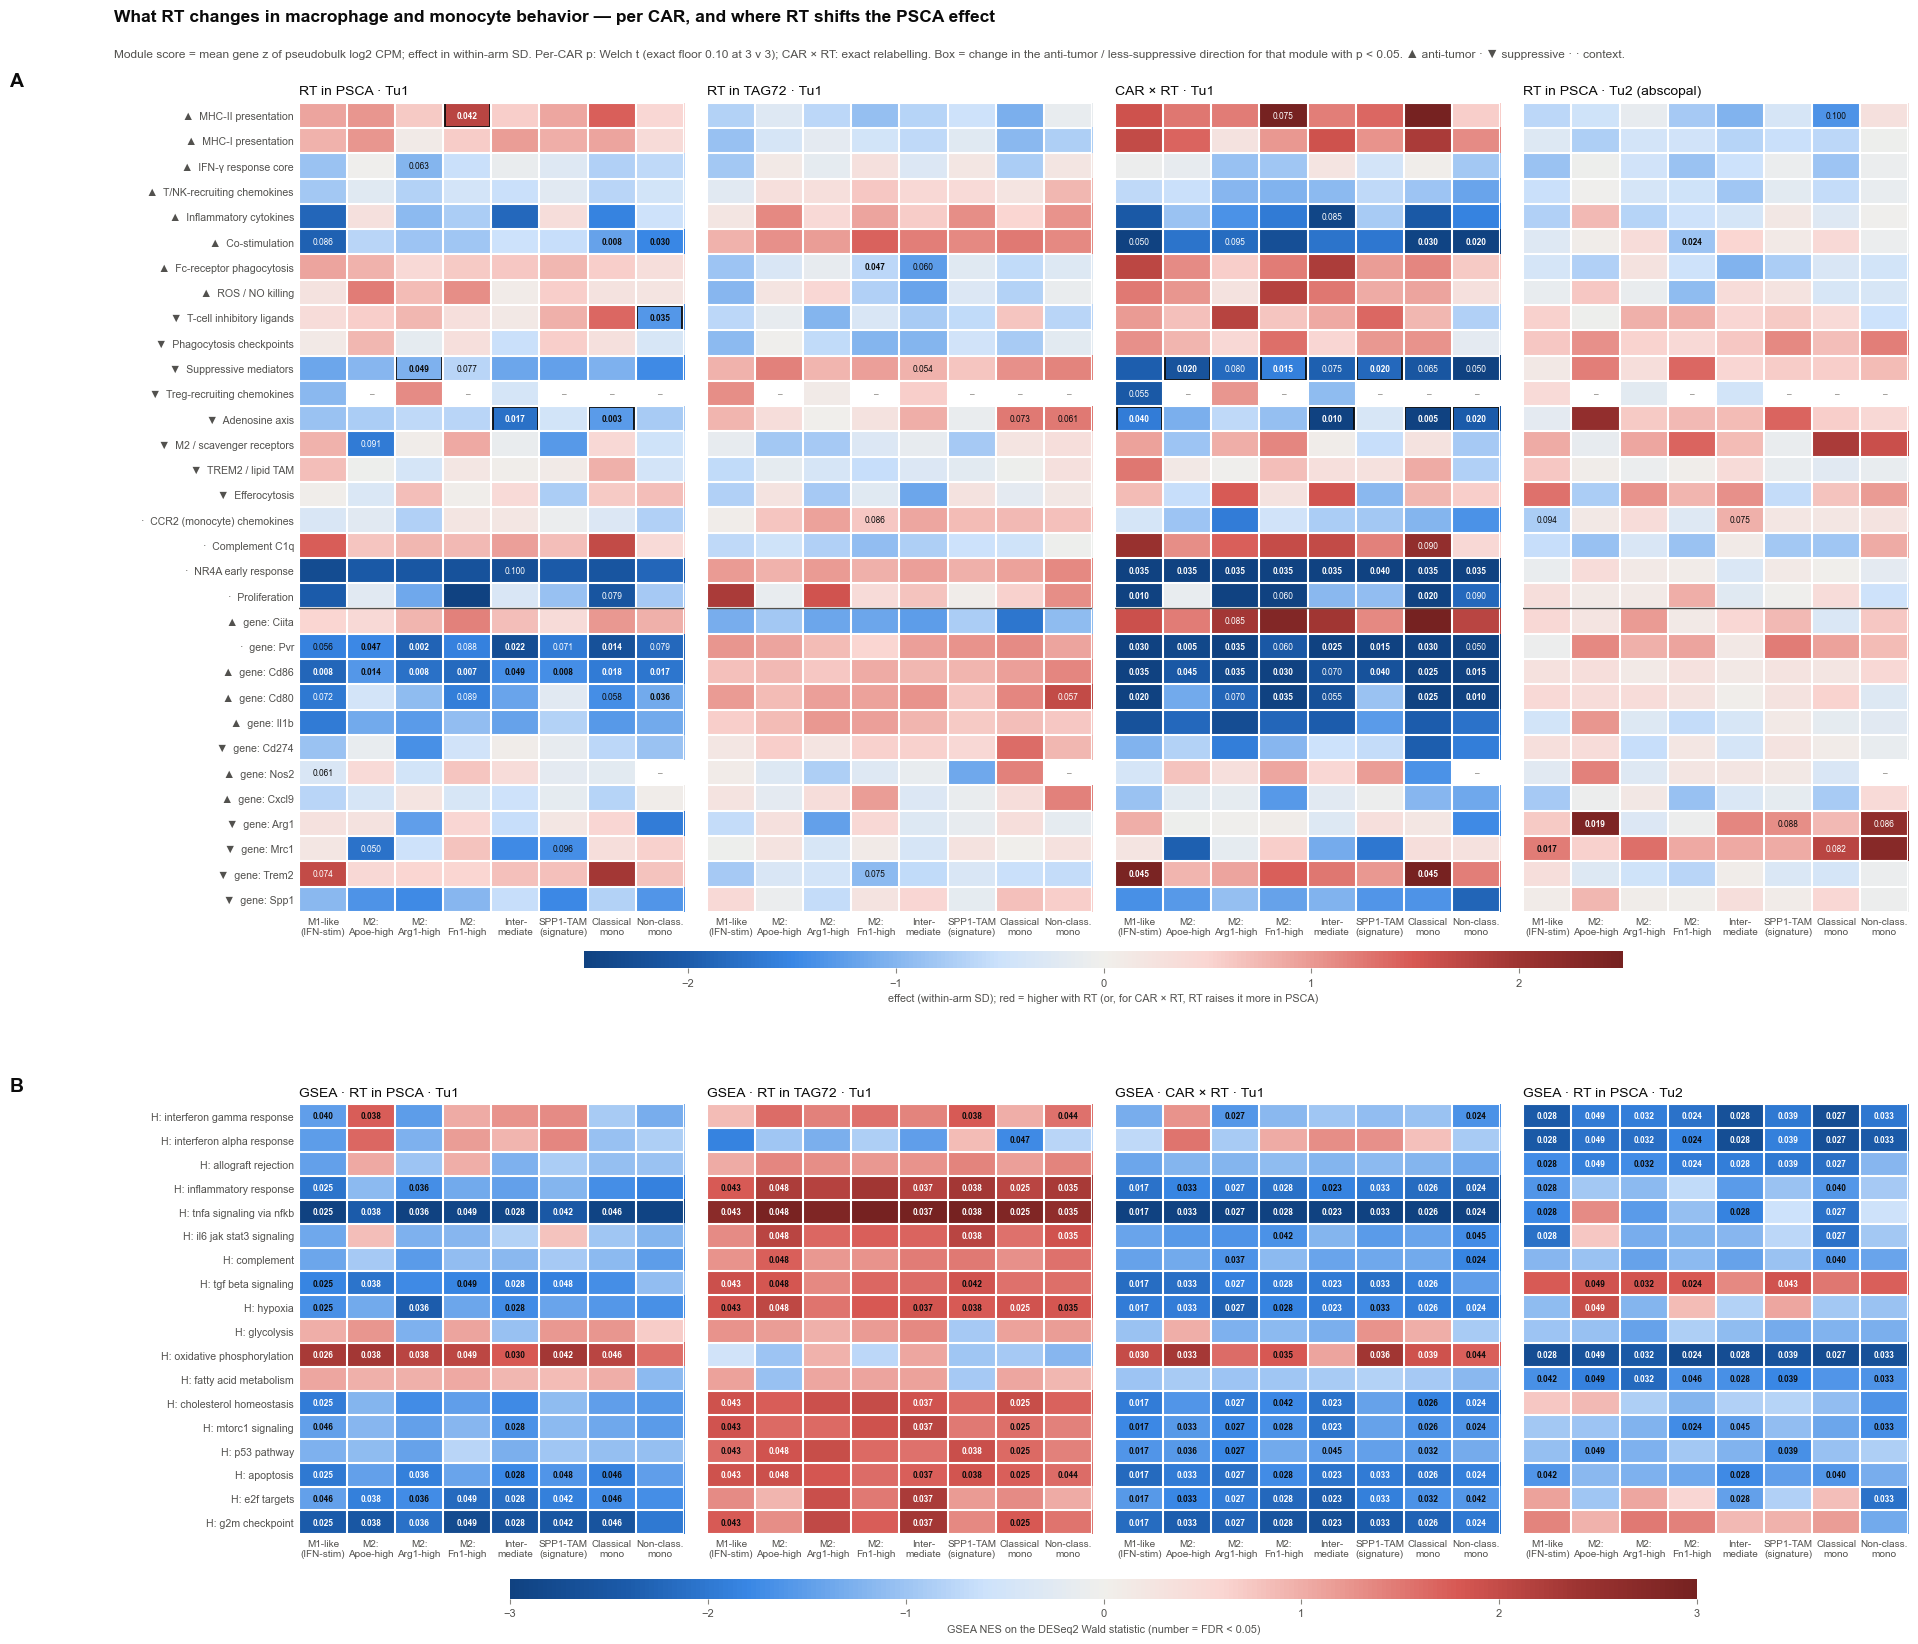

In [13]:
M3_GROUPS = ["IFN_stimulated_Mac", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Intermediate_Mac", "SPP1_TAM",
             "Classical_Mono", "Nonclassical_Mono"]
ROWS3 = MOD_ROWS + [f"gene: {g}" for g in SPOT]


def mat(eff, part, k):
    d = MOD[(MOD.effect == eff) & (MOD.part == part)]
    return d.pivot(index="module", columns="group", values=k).reindex(index=ROWS3, columns=M3_GROUPS)


VIEWS = [("RT Tu1", "PSCA", "RT in PSCA · Tu1"), ("RT Tu1", "TAG72", "RT in TAG72 · Tu1"),
         ("RT Tu1", "CARxRT", "CAR × RT · Tu1"), ("RT Tu2", "PSCA", "RT in PSCA · Tu2 (abscopal)")]
fig = plt.figure(figsize=(18.5, 17))
gs = GridSpec(2, 1, height_ratios=[1.75, 1.0], hspace=0.2, left=0.12, right=0.99, top=0.93, bottom=0.05)
fig.suptitle("What RT changes in macrophage and monocyte behavior — per CAR, and where RT shifts the PSCA effect",
             x=0.02, y=0.985, ha="left", fontsize=12.5, weight="bold")
fig.text(0.02, 0.957, "Module score = mean gene z of pseudobulk log2 CPM; effect in within-arm SD. Per-CAR p: Welch t "
         "(exact floor 0.10 at 3 v 3); CAR × RT: exact relabelling. Box = change in the anti-tumor / less-suppressive "
         "direction for that module with p < 0.05. ▲ anti-tumor · ▼ suppressive · · context.", fontsize=8.6, color=INK2)
top = GridSpecFromSubplotSpec(1, 4, gs[0], wspace=0.06)
for k, (eff, part, title) in enumerate(VIEWS):
    ax = fig.add_subplot(top[k])
    E, P = mat(eff, part, "est"), mat(eff, part, "p_use")
    ori = pd.Series([ORI.get(r, 0) for r in ROWS3], index=ROWS3)
    BOX = (E.mul(ori, axis=0) > 0) & (P < 0.05)
    im = heat(ax, E, P, vmax=2.5, p_show=0.10, box=BOX, fs=6.0,
              row_labels=[f"{TAG[ORI[r]]}  {r}" if r in ORI else f"    {r}" for r in ROWS3] if k == 0 else [""] * len(ROWS3),
              col_labels=[BEH[g] for g in M3_GROUPS])
    ax.set_title(title, loc="left", fontsize=10)
    if k == 0: ax.text(-0.75, 1.02, "A", transform=ax.transAxes, fontsize=14, weight="bold")
    ax.axhline(len(MOD_ROWS) - 0.5, color=INK2, lw=1.0)
cb = fig.colorbar(im, ax=fig.axes[-4:], orientation="horizontal", fraction=0.02, pad=0.045, aspect=60)
cb.set_label("effect (within-arm SD); red = higher with RT (or, for CAR × RT, RT raises it more in PSCA)", fontsize=7.8, color=INK2)
cb.outline.set_visible(False)

HALL = ["HALLMARK_INTERFERON_GAMMA_RESPONSE", "HALLMARK_INTERFERON_ALPHA_RESPONSE", "HALLMARK_ALLOGRAFT_REJECTION",
        "HALLMARK_INFLAMMATORY_RESPONSE", "HALLMARK_TNFA_SIGNALING_VIA_NFKB", "HALLMARK_IL6_JAK_STAT3_SIGNALING",
        "HALLMARK_COMPLEMENT", "HALLMARK_TGF_BETA_SIGNALING", "HALLMARK_HYPOXIA", "HALLMARK_GLYCOLYSIS",
        "HALLMARK_OXIDATIVE_PHOSPHORYLATION", "HALLMARK_FATTY_ACID_METABOLISM", "HALLMARK_CHOLESTEROL_HOMEOSTASIS",
        "HALLMARK_MTORC1_SIGNALING", "HALLMARK_P53_PATHWAY", "HALLMARK_APOPTOSIS", "HALLMARK_E2F_TARGETS",
        "HALLMARK_G2M_CHECKPOINT"]
bot = GridSpecFromSubplotSpec(1, 4, gs[1], wspace=0.06)
for k, (site, c, title) in enumerate([(1, "RT_in_PSCA", "GSEA · RT in PSCA · Tu1"), (1, "RT_in_TAG72", "GSEA · RT in TAG72 · Tu1"),
                                       (1, "CARxRT", "GSEA · CAR × RT · Tu1"), (2, "RT_in_PSCA", "GSEA · RT in PSCA · Tu2")]):
    ax = fig.add_subplot(bot[k])
    d = GS[(GS.kind == "rt") & (GS.site == site) & (GS.contrast == c)]
    N_ = d.pivot(index="pathway", columns="group", values="NES").reindex(index=HALL, columns=M3_GROUPS)
    Q_ = d.pivot(index="pathway", columns="group", values="FDR").reindex(index=HALL, columns=M3_GROUPS)
    im = heat(ax, N_, Q_, vmax=3.0, p_show=0.05, fs=6.0, row_labels=[short(h) for h in HALL] if k == 0 else [""] * len(HALL),
              col_labels=[BEH[g] for g in M3_GROUPS])
    ax.set_title(title, loc="left", fontsize=10)
    if k == 0: ax.text(-0.75, 1.03, "B", transform=ax.transAxes, fontsize=14, weight="bold")
cb = fig.colorbar(im, ax=fig.axes[-4:], orientation="horizontal", fraction=0.04, pad=0.09, aspect=60)
cb.set_label("GSEA NES on the DESeq2 Wald statistic (number = FDR < 0.05)", fontsize=7.8, color=INK2); cb.outline.set_visible(False)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM3_rt_behavior.{ext}", bbox_inches="tight")
plt.show()

## 11. Part 4 — SPP1-TAMs: what they do, and what they do differently with RT
* **What they do:** paired DESeq2 SPP1-TAM vs the other macrophages in the same tumor (both definitions),
  GSEA and module gaps (Figure M2 columns).
* **What they do differently with RT:**
  - RT effects on the SPP1-TAM pseudobulk itself (module scores and GSEA).
  - RT effects on the **SPP1 gap**: for each tumor, SPP1-TAM minus the other macrophages in the same tumor.
    A change in the gap means RT makes SPP1-TAMs more, or less, different from their neighbors.

SPP1-TAM vs other macrophages — top pathways up:
                                       pathway   NES   FDR
               GOBP_LYTIC_VACUOLE_ORGANIZATION 2.404 0.034
           GOBP_GLYCOPROTEIN_CATABOLIC_PROCESS 2.346 0.034
                 REACTOME_COLLAGEN_DEGRADATION 2.320 0.034
                   REACTOME_COLLAGEN_FORMATION 2.281 0.034
          REACTOME_AMINO_ACIDS_REGULATE_MTORC1 2.280 0.034
                   GOBP_VACUOLAR_ACIDIFICATION 2.263 0.034
            REACTOME_IRON_UPTAKE_AND_TRANSPORT 2.239 0.034
REACTOME_TRANSFERRIN_ENDOCYTOSIS_AND_RECYCLING 2.215 0.034
down:
                                                                            pathway    NES   FDR
                                       REACTOME_RIBOSOME_ASSOCIATED_QUALITY_CONTROL -2.550 0.034
                                                             REACTOME_MRNA_SPLICING -2.434 0.034
                                                             REACTOME_TCR_SIGNALING -2.404 0.034
                          

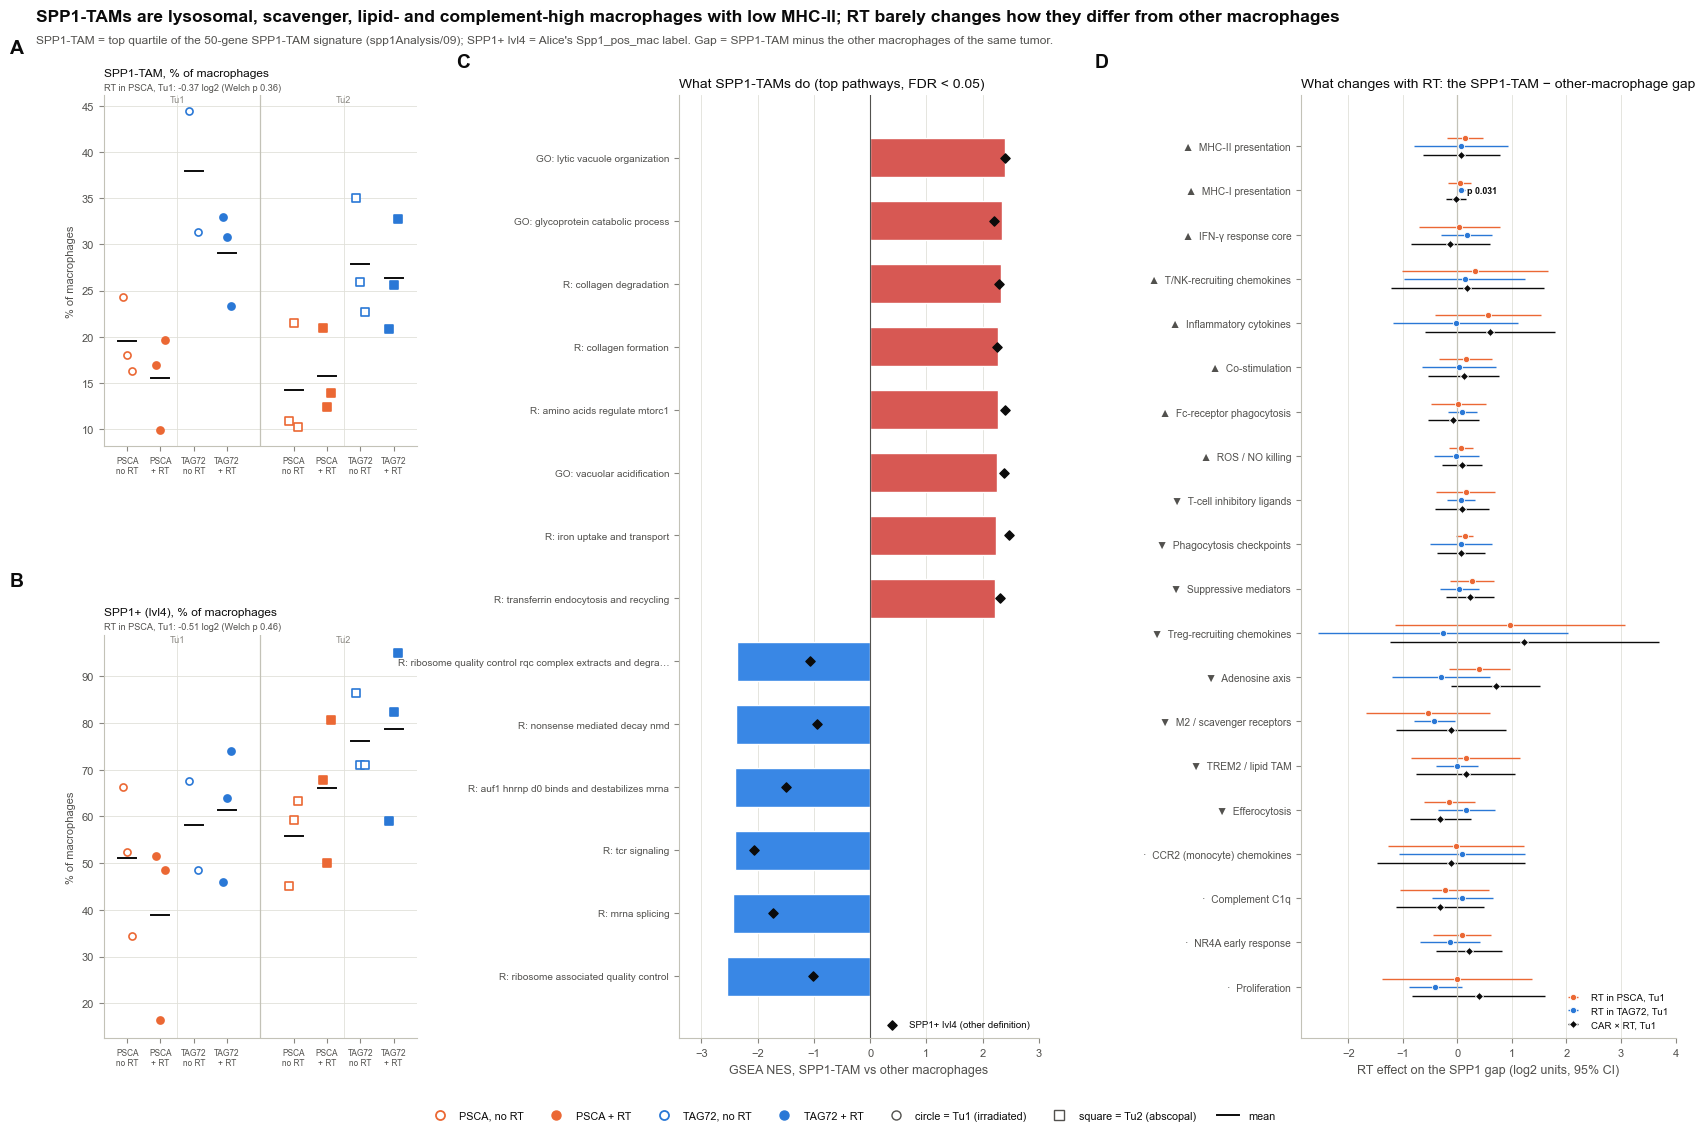

In [14]:
gap_rows = []
for st_ in ["SPP1_TAM", "SPP1_alice"]:
    G = GAPS[st_]; gm = FEAT.loc[G.index, ["arm", "site"]]
    for col in G.columns:
        gap_rows += effect_rows(G[col], gm, group=st_, module=col)
GAP = pd.DataFrame(gap_rows)
GAP["orientation"] = GAP.module.map(lambda m: ORI.get(m, 0)); GAP["p_use"] = GAP.apply(best_p, axis=1)
GAP["advantage"] = GAP.orientation * GAP.est
GAP.to_csv(OUT/"spp1_gap_effects.csv", index=False)

top_spp1 = GS[(GS.kind == "state") & (GS.group == "SPP1_TAM") & (GS.FDR < 0.05)]
up = top_spp1.nlargest(8, "NES"); dn = top_spp1.nsmallest(6, "NES")
print("SPP1-TAM vs other macrophages — top pathways up:"); print(up[["pathway", "NES", "FDR"]].round(3).to_string(index=False))
print("down:"); print(dn[["pathway", "NES", "FDR"]].round(3).to_string(index=False))

fig = plt.figure(figsize=(17, 11.5))
gs = GridSpec(2, 3, height_ratios=[1, 1.15], width_ratios=[1.0, 1.15, 1.2], hspace=0.5, wspace=0.75,
              left=0.06, right=0.985, top=0.9, bottom=0.08)
fig.suptitle("SPP1-TAMs are lysosomal, scavenger, lipid- and complement-high macrophages with low MHC-II; RT barely changes "
             "how they differ from other macrophages",
             x=0.02, y=0.975, ha="left", fontsize=12.5, weight="bold")
fig.text(0.02, 0.945, "SPP1-TAM = top quartile of the 50-gene SPP1-TAM signature (spp1Analysis/09); SPP1+ lvl4 = Alice's "
         "Spp1_pos_mac label. Gap = SPP1-TAM minus the other macrophages of the same tumor.", fontsize=8.6, color=INK2)
ax = fig.add_subplot(gs[0, 0]); ax.text(-0.3, 1.12, "A", transform=ax.transAxes, fontsize=14, weight="bold")
est = cget("SPP1_TAM", "% of macrophages", "RT Tu1", "PSCA", "est"); pw = cget("SPP1_TAM", "% of macrophages", "RT Tu1", "PSCA", "welch")
strip_sites(ax, FEAT["SPP1_TAM | % of macrophages"], meta_s, "SPP1-TAM, % of macrophages", ylab="% of macrophages",
            annot=f"RT in PSCA, Tu1: {est:+.2f} log2 (Welch p {fmt_p(pw)})")
ax = fig.add_subplot(gs[1, 0]); ax.text(-0.3, 1.12, "B", transform=ax.transAxes, fontsize=14, weight="bold")
est = cget("SPP1_alice", "% of macrophages", "RT Tu1", "PSCA", "est"); pw = cget("SPP1_alice", "% of macrophages", "RT Tu1", "PSCA", "welch")
strip_sites(ax, FEAT["SPP1_alice | % of macrophages"], meta_s, "SPP1+ (lvl4), % of macrophages", ylab="% of macrophages",
            annot=f"RT in PSCA, Tu1: {est:+.2f} log2 (Welch p {fmt_p(pw)})")

ax = fig.add_subplot(gs[:, 1]); ax.text(-0.62, 1.03, "C", transform=ax.transAxes, fontsize=14, weight="bold")
sel = pd.concat([up, dn]).sort_values("NES")
alt = GS[(GS.kind == "state") & (GS.group == "SPP1_alice")].set_index("pathway").NES
y = np.arange(len(sel))
ax.barh(y, sel.NES, color=[ "#d75853" if v > 0 else "#3987e5" for v in sel.NES], height=0.62, edgecolor="white")
ax.scatter(alt.reindex(sel.pathway).values, y, marker="D", s=22, color=INK, zorder=3, label="SPP1+ lvl4 (other definition)")
ax.set_yticks(y); ax.set_yticklabels([short(p) for p in sel.pathway], fontsize=7.2)
ax.axvline(0, color=INK2, lw=0.8); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("GSEA NES, SPP1-TAM vs other macrophages"); ax.set_xlim(-3.4, 3.0)
ax.set_title("What SPP1-TAMs do (top pathways, FDR < 0.05)", loc="left", fontsize=10)
ax.legend(loc="lower right", frameon=False, fontsize=7)

ax = fig.add_subplot(gs[:, 2]); ax.text(-0.55, 1.03, "D", transform=ax.transAxes, fontsize=14, weight="bold")
rowsD = [m for m in MOD_ROWS]
yy = np.arange(len(rowsD))[::-1]
for (eff, part, col_, off, lab) in [("RT Tu1", "PSCA", C_PSCA, 0.18, "RT in PSCA, Tu1"), ("RT Tu1", "TAG72", C_TAG72, 0.0, "RT in TAG72, Tu1"),
                                    ("RT Tu1", "CARxRT", INK, -0.2, "CAR × RT, Tu1")]:
    d = GAP[(GAP.group == "SPP1_TAM") & (GAP.effect == eff) & (GAP.part == part)].set_index("module").reindex(rowsD)
    ax.errorbar(d.est, yy + off, xerr=[d.est - d.lo, d.hi - d.est], fmt="D" if part == "CARxRT" else "o", color=col_,
                ms=4.5, lw=1.0, capsize=0, label=lab, mec="white", mew=0.6)
    for i, r in enumerate(d.itertuples()):
        if np.isfinite(r.p_use) and r.p_use < 0.05:
            ax.text(r.hi + 0.05, yy[i] + off, f"p {fmt_p(r.p_use)}", fontsize=6.4, va="center", color=INK, weight="bold")
ax.axvline(0, color=AXIS, lw=0.9); ax.set_yticks(yy); ax.set_yticklabels([f"{TAG[ORI[m]]}  {m}" for m in rowsD], fontsize=7.4)
ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("RT effect on the SPP1 gap (log2 units, 95% CI)")
ax.set_title("What changes with RT: the SPP1-TAM − other-macrophage gap", loc="left", fontsize=10)
ax.legend(loc="lower right", frameon=False, fontsize=7)
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM4_spp1_tams.{ext}", bbox_inches="tight")
plt.show()

## 12. Part 5 — scorecard: RT effects that point toward more killing or less suppression
Every test from composition, module scores and the SPP1 gap. A row counts when p < 0.05. **Advantage** = moves in the
anti-tumor / less-suppressive direction for that readout. Chance expectation = 5% of the tests in each family.
Composition orientation:
* **Anti-tumor:** M1-like, IFN-stim monocytes, M1:M2 ratio.
* **Suppressive:** Apoe-, Arg1-, Fn1-high, SPP1-TAM.
* **Context:** the rest.

Hits (p < 0.05) vs chance, by family and contrast:
                                tests  p05  expected  advantage  against  context
family       contrast                                                            
SPP1 gap     Tu1 · CAR × RT        64    1       3.2        1.0      0.0      0.0
             Tu1 · RT in PSCA      64    0       3.2        0.0      0.0      0.0
             Tu1 · RT in TAG72     64    2       3.2        2.0      0.0      0.0
             Tu1 · RT pooled       64    2       3.2        1.0      1.0      0.0
             Tu2 · CAR × RT        64    4       3.2        1.0      1.0      2.0
             Tu2 · RT in PSCA      64    3       3.2        0.0      1.0      2.0
             Tu2 · RT in TAG72     64    5       3.2        1.0      4.0      0.0
             Tu2 · RT pooled       64    3       3.2        0.0      3.0      0.0
composition  Tu1 · CAR × RT        31    0       1.6        0.0      0.0      0.0
             Tu1 · RT in PSCA      31    2     

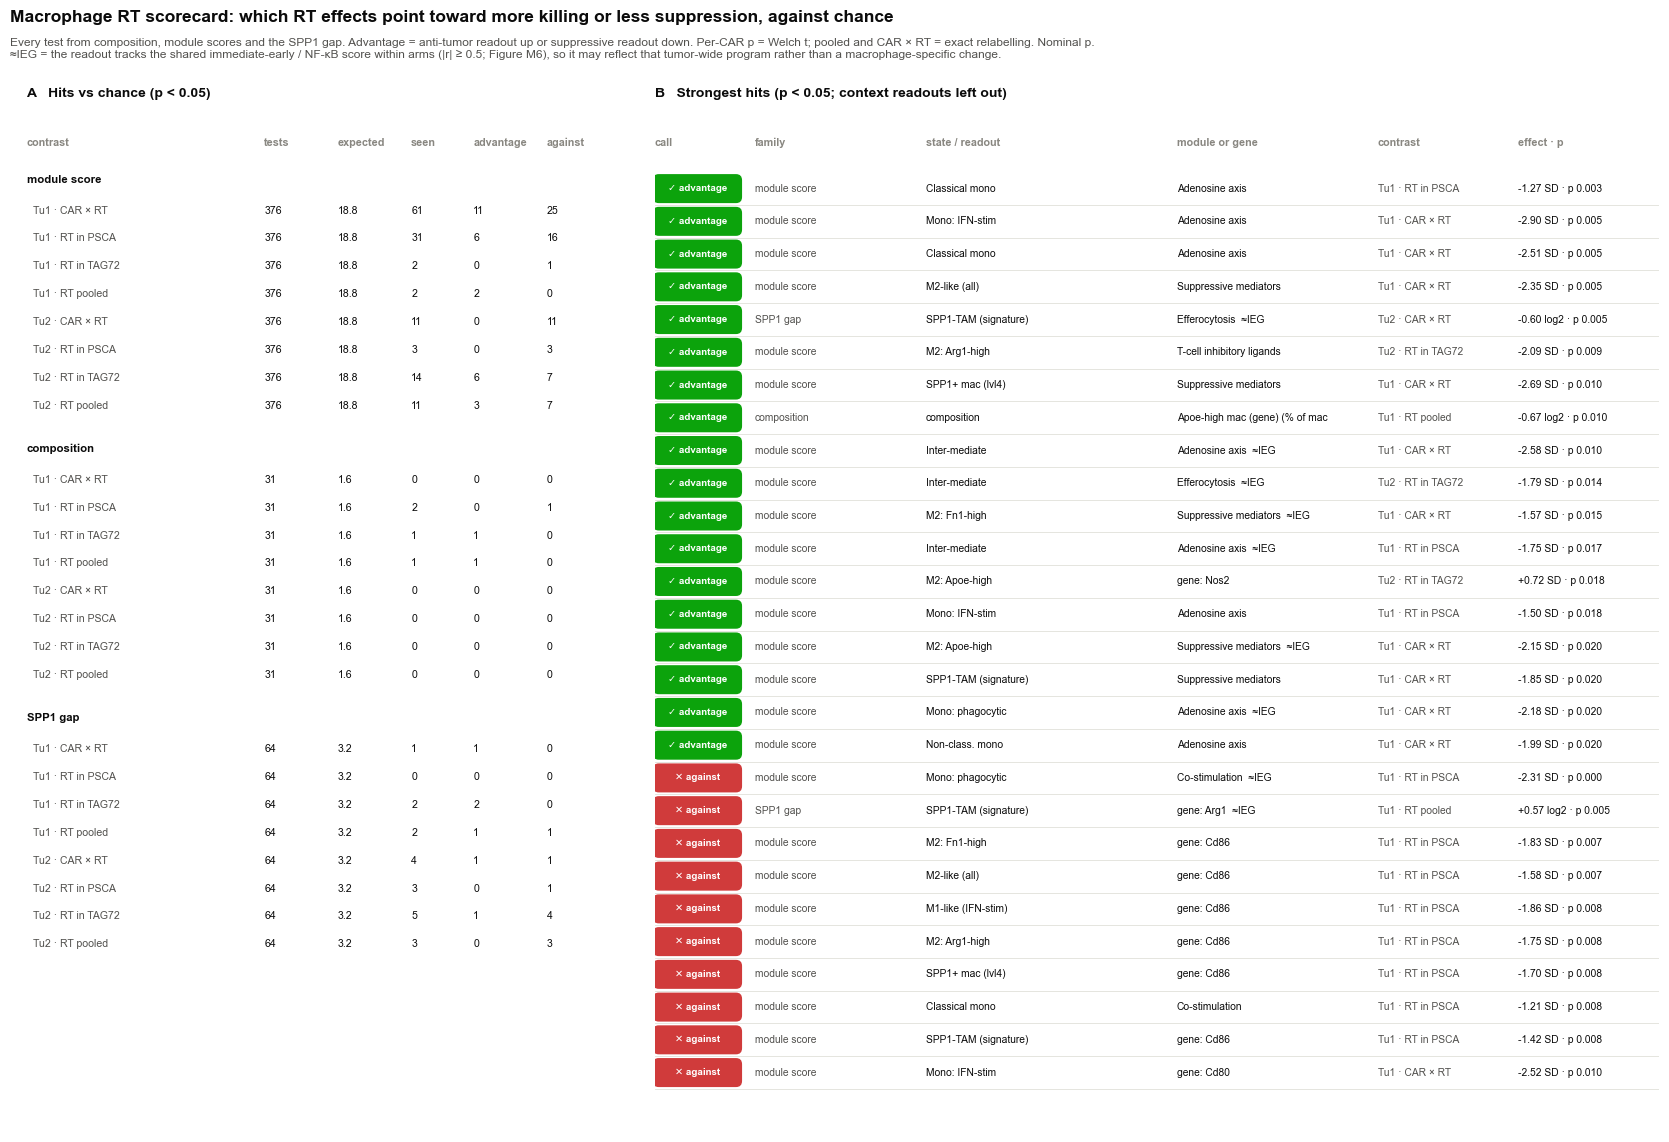

In [15]:
COMP_ORI = {"IFN_stimulated_Mac": 1, "M1_like_Mac": 1, "IFN_stimulated_Mono": 1, "log2 M1:M2": 1,
            "Apoe_high_Mac": -1, "Arg1_high_Mac": -1, "Fn1_high_Mac": -1, "M2_like_Mac": -1, "SPP1_TAM": -1, "SPP1_alice": -1,
            "Spp1_high": -1, "Trem2_high": -1, "Spp1_Trem2_high": -1, "Spp1_Trem2_Apoe_high": -1, "Apoe_high": -1}
RT_PARTS = [("RT Tu1", "PSCA"), ("RT Tu1", "TAG72"), ("RT Tu1", "pooled"), ("RT Tu1", "CARxRT"),
            ("RT Tu2", "PSCA"), ("RT Tu2", "TAG72"), ("RT Tu2", "pooled"), ("RT Tu2", "CARxRT")]
# (PSCA-side CAR x RT is the same interaction as the RT-side one, so it is not counted twice)


def tag_rt(df, what):
    d = df[df.apply(lambda r: (r.effect, r.part) in RT_PARTS, axis=1)].copy()
    d["family"] = what
    return d


cc_ = tag_rt(COMP[COMP.denominator.isin(["% of mono/mac", "% of parent", "% of macrophages", "ratio"])], "composition")
cc_["orientation"] = cc_.feature.map(lambda f: COMP_ORI.get(f, 0)); cc_["module"] = cc_.feature + " (" + cc_.denominator + ")"
cc_["group"] = "—"
cc_["module"] = [f"{SUB_NAME.get(f, f)} ({d})" for f, d in zip(cc_.feature, cc_.denominator)]
mm_ = tag_rt(MOD, "module score")
gg_ = tag_rt(GAP, "SPP1 gap")
ALL = pd.concat([cc_, mm_, gg_], ignore_index=True)
ALL["orientation"] = [ORI.get(m, o) if f != "composition" else o for f, m, o in zip(ALL.family, ALL.module, ALL.orientation)]
ALL["site_"] = ALL.effect.str[-1].astype(int)
ALL = ALL.merge(IEGR.rename(columns={"site": "site_"}), on=["group", "module", "site_"], how="left")
ALL["tracks_IEG"] = ALL.ieg_r.abs() >= 0.5
ALL["advantage"] = ALL.orientation * ALL.est
ALL["call"] = np.where(ALL.orientation == 0, "context", np.where(ALL.advantage > 0, "advantage", "against"))
ALL["contrast"] = ALL.effect.str.replace("RT ", "") + " · " + ALL.part.map({"PSCA": "RT in PSCA", "TAG72": "RT in TAG72",
                                                                            "pooled": "RT pooled", "CARxRT": "CAR × RT"})
ALL = ALL.drop_duplicates(subset=["family", "group", "module", "effect", "part"])
ALL.drop(columns=["null"], errors="ignore").to_csv(OUT/"scorecard_all_tests.csv", index=False)
CH = ALL.groupby(["family", "contrast"]).agg(tests=("p_use", "count"), p05=("p_use", lambda x: int((x < 0.05).sum())))
CH["expected"] = (CH.tests * 0.05).round(1)
adv = ALL[(ALL.p_use < 0.05)].groupby(["family", "contrast", "call"]).size().unstack(fill_value=0)
CH = CH.join(adv).fillna(0)
CH.to_csv(OUT/"scorecard_chance.csv")
print("Hits (p < 0.05) vs chance, by family and contrast:"); print(CH.to_string())
HITS = ALL[(ALL.p_use < 0.05) & (ALL.call != "context")].sort_values("p_use")
HITS.drop(columns=["null"], errors="ignore").to_csv(OUT/"scorecard_hits.csv", index=False)

# ---- figure M5: scorecard ----
fig = plt.figure(figsize=(17, 12))
gs = GridSpec(1, 2, width_ratios=[0.9, 1.6], wspace=0.08, left=0.03, right=0.99, top=0.9, bottom=0.04)
fig.suptitle("Macrophage RT scorecard: which RT effects point toward more killing or less suppression, against chance",
             x=0.02, y=0.975, ha="left", fontsize=12.5, weight="bold")
fig.text(0.02, 0.935, "Every test from composition, module scores and the SPP1 gap. Advantage = anti-tumor readout up or "
         "suppressive readout down. Per-CAR p = Welch t; pooled and CAR × RT = exact relabelling. Nominal p.\n"
         "≈IEG = the readout tracks the shared immediate-early / NF-κB score within arms (|r| ≥ 0.5; Figure M6), so it may "
         "reflect that tumor-wide program rather than a macrophage-specific change.", fontsize=8.6, color=INK2)
ax = fig.add_subplot(gs[0]); ax.axis("off")
ax.text(0.0, 1.0, "A   Hits vs chance (p < 0.05)", transform=ax.transAxes, fontsize=10, va="bottom", weight="bold")
heads = ["contrast", "tests", "expected", "seen", "advantage", "against"]
xs = [0.0, 0.42, 0.55, 0.68, 0.79, 0.92]
for x, h in zip(xs, heads): ax.text(x, 0.955, h, transform=ax.transAxes, fontsize=7.8, color=MUTED, weight="bold")
yy0 = 0.92
for fam in ["module score", "composition", "SPP1 gap"]:
    d = CH.reset_index(); d = d[d.family == fam]
    ax.text(0.0, yy0, fam, transform=ax.transAxes, fontsize=8.2, weight="bold", color=INK); yy0 -= 0.03
    for r in d.itertuples():
        vals = [r.contrast, f"{r.tests}", f"{r.expected:.1f}", f"{r.p05}", f"{int(getattr(r, 'advantage', 0))}", f"{int(getattr(r, 'against', 0))}"]
        for x, v in zip(xs, vals):
            ax.text(x + (0.01 if x == 0 else 0), yy0, v, transform=ax.transAxes, fontsize=7.6, color=INK2 if x == 0 else INK)
        yy0 -= 0.027
    yy0 -= 0.015
ax2 = fig.add_subplot(gs[1]); ax2.axis("off")
ax2.text(0.0, 1.0, "B   Strongest hits (p < 0.05; context readouts left out)", transform=ax2.transAxes, fontsize=10, va="bottom", weight="bold")
cols_x = [0.0, 0.1, 0.27, 0.52, 0.72, 0.86]
for x, h in zip(cols_x, ["call", "family", "state / readout", "module or gene", "contrast", "effect · p"]):
    ax2.text(x, 0.955, h, transform=ax2.transAxes, fontsize=7.8, color=MUTED, weight="bold")
show_h = pd.concat([HITS[HITS.call == "advantage"].head(18), HITS[HITS.call == "against"].head(10)])
dy = 0.92 / max(len(show_h) + 1, 1)
for i, r in enumerate(show_h.itertuples()):
    y = 0.93 - (i + 0.5) * dy
    fc, tc, ic = (S_GOOD, "white", "✓") if r.call == "advantage" else (S_CRIT, "white", "✕")
    ax2.add_patch(mpl.patches.FancyBboxPatch((0.0, y - dy * 0.38), 0.085, dy * 0.76, boxstyle="round,pad=0.002,rounding_size=0.006",
                                             transform=ax2.transAxes, facecolor=fc, edgecolor="none"))
    ax2.text(0.0425, y, f"{ic} {r.call}", transform=ax2.transAxes, ha="center", va="center", fontsize=7, color=tc, weight="bold")
    grp = flat(BEH.get(r.group, r.group)) if r.group != "—" else "composition"
    unit = "log2" if r.family in ("composition", "SPP1 gap") else "SD"
    ax2.text(cols_x[1], y, r.family, transform=ax2.transAxes, va="center", fontsize=7.4, color=INK2)
    ax2.text(cols_x[2], y, grp, transform=ax2.transAxes, va="center", fontsize=7.4, color=INK)
    ax2.text(cols_x[3], y, str(r.module)[:30] + ("  ≈IEG" if r.tracks_IEG else ""), transform=ax2.transAxes, va="center",
             fontsize=7.4, color=INK)
    ax2.text(cols_x[4], y, r.contrast, transform=ax2.transAxes, va="center", fontsize=7.4, color=INK2)
    ax2.text(cols_x[5], y, f"{r.est:+.2f} {unit} · p {fmt_p(r.p_use)}", transform=ax2.transAxes, va="center", fontsize=7.4, color=INK)
    ax2.plot([0, 1], [y - dy / 2] * 2, transform=ax2.transAxes, color=GRID, lw=0.6)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureM5_scorecard.{ext}", bbox_inches="tight")
plt.show()

## 13. Summary

In [16]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print("\n[1] Composition (p < 0.10; mono/mac, parent, macrophage and ratio denominators):")
print(show[["feature", "denominator", "effect", "part", "est", "p_use", "q"]].round(3).to_string(index=False))
print("\n[1b] Spp1-/Trem2-high shares, PSCA − TAG72 pooled over RT (log2 FC, exact p):")
print(COMP[COMP.feature.isin(list(HIGHS)) & (COMP.denominator == "% of macrophages") & (COMP.part == "pooled") & COMP.effect.str.startswith("PSCA")]
      [["feature", "effect", "est", "p"]].round(3).to_string(index=False))
print("[1b] decomposition (pp):"); print(DECE[DECE.part == "pooled"][["high", "component", "effect", "est_pp", "p"]].round(3).to_string(index=False))
print("\n[2] State identity — strongest module gaps (|mean log2| >= 0.5, q < 0.05):")
print(IDN[(IDN.module.isin(MODULES)) & (IDN.q < 0.05) & (IDN.mean_log2.abs() >= 0.5)]
      .sort_values(["state", "mean_log2"])[["state", "module", "mean_log2", "frac_same_sign", "q"]].round(3).to_string(index=False))
print("\n[3] RT behavior — hits vs chance:"); print(CH.to_string())
print("\n[3] Top advantage hits:"); print(HITS[HITS.call == "advantage"].head(25)[["family", "group", "module", "contrast", "est", "p_use", "q", "ieg_r"]].round(3).to_string(index=False))
print("\n[3] Top against hits:"); print(HITS[HITS.call == "against"].head(15)[["family", "group", "module", "contrast", "est", "p_use", "q", "ieg_r"]].round(3).to_string(index=False))
print("\n[8c] IEG score CAR x RT per compartment:"); print(IEGE[IEGE.part == "CARxRT"][["group", "effect", "est", "p"]].round(3).to_string(index=False))
print(f"[8c] same-mouse Tu1-Tu2 rho {pair_r.correlation:.2f} p {pair_r.pvalue:.3f}; within arm {pair_rc.correlation:.2f} p {pair_rc.pvalue:.3f}")
print("[8c] adjusted CAR x RT:"); print(ADJ.round(2).to_string(index=False))
print("\n[3] Hallmark GSEA at FDR < 0.05 in RT contrasts (macrophage groups):")
h = GS[(GS.kind == "rt") & GS.pathway.str.startswith("HALLMARK") & (GS.FDR < 0.05)]
print(h.sort_values(["contrast", "site", "group"])[["group", "site", "contrast", "pathway", "NES", "FDR"]].round(3).to_string(index=False))
print("\n[4] SPP1-TAM vs other macrophages, top pathways:"); print(pd.concat([up, dn])[["pathway", "NES", "FDR"]].round(3).to_string(index=False))
print("\n[4] SPP1 gap RT effects, p < 0.05:")
print(GAP[GAP.p_use < 0.05][["group", "module", "effect", "part", "est", "p_use", "advantage"]].round(3).to_string(index=False))
print(f"\n[files] {OUT}")
print("=" * 100)

SUMMARY — report these back

[1] Composition (p < 0.10; mono/mac, parent, macrophage and ratio denominators):
               feature      denominator   effect   part    est  p_use     q
    IFN_stimulated_Mac    % of mono/mac   RT Tu1   PSCA  0.373  0.094 0.424
    IFN_stimulated_Mac    % of mono/mac PSCA Tu1 pooled  0.740  0.005 0.010
    IFN_stimulated_Mac    % of mono/mac PSCA Tu2  no RT  1.211  0.019 0.112
    IFN_stimulated_Mac    % of mono/mac PSCA Tu2     RT  0.804  0.020 0.116
    IFN_stimulated_Mac    % of mono/mac PSCA Tu2 pooled  1.008  0.005 0.015
         Apoe_high_Mac    % of mono/mac PSCA Tu1  no RT -1.148  0.016 0.049
         Apoe_high_Mac    % of mono/mac PSCA Tu1 pooled -0.884  0.015 0.025
         Apoe_high_Mac    % of mono/mac PSCA Tu2  no RT -1.016  0.063 0.162
         Apoe_high_Mac    % of mono/mac PSCA Tu2 pooled -0.877  0.010 0.023
         Arg1_high_Mac      % of parent PSCA Tu1  no RT  0.681  0.084 0.150
         Arg1_high_Mac      % of parent PSCA Tu1 poole